# ESTUDIO NUMÉRICO DE ESTABILIDAD DEL ESTADO ESTACIONARIO
## Redes Neuronales de Fase con Desorden Recocido y FluctuACIONES DE TAMAÑO FINITO

---

### 1. Marco Teórico Formal

#### 1.1. Ecuación de Continuidad y Dinámica en el Límite Termodinámico
Consideramos una población heterogénea de neuronas de fase acopladas globalmente a través de impulsos sinápticos mediados por eventos de disparo. En el límite termodinámico ($N \to \infty$), la densidad de probabilidad $\rho(\phi, t)$ de encontrar una neurona con fase $\phi \in [0, 2\pi)$ al tiempo $t$ satisface la ecuación de continuidad (o Fokker-Planck sin ruido térmico):

$$
\frac{\partial \rho(\phi, t)}{\partial t} + \frac{\partial}{\partial \phi} \left[ V(\phi, t) \, \rho(\phi, t) \right] = 0
$$

donde la velocidad de fase macroscópica está gobernada por:
$$
V(\phi, t) = v + p(t) \, Z(\phi)
$$

Aquí:
* $v$ representa la velocidad de fase intrínseca base de los osciladores libres. A lo largo de todo este estudio numérico fijaremos estrictamente:
  $$v = 2.0$$
  lo cual define un tiempo de vuelo libre de referencia $T_{\rm libre} = \frac{2\pi}{v} = \pi$.
* $Z(\phi)$ es la curva de respuesta de fase (PRC, por sus siglas en inglés *Phase Response Curve*), periódica en $\phi \in [0, 2\pi]$.
* $p(t)$ es el campo medio de acoplamiento instantáneo generado por los disparos de la red:
  $$
  p(t) = \frac{\mu_\omega \, v \, \rho(0, t)}{1 - \mu_\omega \, Z(0) \, \rho(0, t)}
  $$
  donde $\mu_\omega$ es la constante global de acoplamiento sináptico medio del sistema.

Para PRCs que satisfacen la condición de anulación en el origen $Z(0) = 0$, el denominador se reduce a la unidad, simplificándose el acoplamiento a:
$$
p(t) = \mu_\omega \, v \, \rho(0, t)
$$

---

#### 1.2. Estado Estacionario $\rho_e(\phi)$ y Acoplamiento Autoconsistente $p_e$
En el estado asintótico estacionario $\partial_t \rho_e = 0$, el flujo de probabilidad $J$ a través de la fase es constante en todo el círculo $\phi \in [0, 2\pi]$:
$$
J = V(\phi) \, \rho_e(\phi) = \text{cte}
$$

De este modo, la distribución estacionaria de fases toma la forma universal:
$$
\rho_e(\phi) = \frac{J}{V(\phi)} = \frac{J}{v + p_e \, Z(\phi)}
$$

Dado que $Z(0) = 0$, la velocidad efectiva en el punto de disparo es $V(0) = v$, lo que implica que la densidad estacionaria en el origen es:
$$
\rho_e(0) = \frac{J}{V(0)} = \frac{J}{v}
$$

Sustituyendo este resultado en la definición del campo medio instantáneo obtenemos el **acoplamiento estacionario constante**:
$$
p_e = \mu_\omega \, v \, \rho_e(0) = \mu_\omega \, v \left( \frac{J}{v} \right) = \mu_\omega \, J
$$

Por lo tanto, la velocidad efectiva estacionaria queda parametrizada exclusivamente por $J$ y el acoplamiento $\mu_\omega$:
$$
V(\phi) = v + \mu_\omega \, J \, Z(\phi)
$$

---

#### 1.3. Condición de Normalización y Ecuación para el Flujo $J$
La conservación de la probabilidad total sobre el ciclo de oscilación $\int_0^{2\pi} \rho_e(\phi) \, d\phi = 1$ impone la siguiente condición integral autoconsistente no lineal para determinar el flujo $J$:

$$
J \int_0^{2\pi} \frac{d\phi}{v + \mu_\omega \, J \, Z(\phi)} = 1
$$

##### Solución Analítica Cerrada para el Modelo QIF
Para el modelo Quadratic Integrate-and-Fire (QIF), la PRC canónica es $Z_{\rm QIF}(\phi) = \sin^2(\phi/2)$. En este caso, la integral de normalización admite solución analítica exacta:
$$
\int_0^{2\pi} \frac{d\phi}{v + \mu_\omega \, J \, \sin^2(\phi/2)} = \frac{2\pi}{\sqrt{v(v + \mu_\omega \, J)}}
$$

Igualando a $\frac{1}{J}$ y elevando al cuadrado se obtiene la ecuación algebraica cuadrática para $J$:
$$
4\pi^2 J^2 - v\,\mu_\omega \, J - v^2 = 0
$$

cuya única raíz física positiva (con flujo unidireccional $J > 0$) es:
$$
J_{\rm exacto} = \frac{v\,\mu_\omega + \sqrt{v^2 \mu_\omega^2 + 16 \pi^2 v^2}}{8 \pi^2}
$$
Esta expresión sirve como contraste y validación analítica rigurosa frente a la resolución numérica por búsqueda de ceros.

---

#### 1.4. Tiempos de Vuelo y Simetrías
El tiempo de vuelo acumulado $T(\phi)$ que le toma a un oscilador recorrer desde la fase inicial $\phi' = 0$ hasta una fase arbitraria $\phi \in [0, 2\pi]$ bajo la velocidad estacionaria $V(\phi')$ está definido por:
$$
T(\phi) = \int_0^\phi \frac{d\phi'}{V(\phi')} = \int_0^\phi \frac{d\phi'}{v + \mu_\omega \, J \, Z(\phi')}
$$

Consecuencias físicas y simetrías fundamentales:
1. **Período de Oscilación Estacionario:** El tiempo para completar una revolución completa alrededor del círculo es:
   $$
   T(2\pi) = \int_0^{2\pi} \frac{d\phi'}{V(\phi')} = \frac{1}{J}
   $$
2. **Simetría Reflexiva:** Cuando la PRC es par respecto al punto medio, $Z(\phi) = Z(2\pi - \phi)$, la velocidad satisface $V(\phi) = V(2\pi - \phi)$. Esto implica que el tiempo para alcanzar la mitad del ciclo $\phi = \pi$ es exactamente la mitad del período total:
   $$
   T(\pi) = \int_0^\pi \frac{d\phi'}{V(\phi')} = \frac{1}{2} \, T(2\pi) = \frac{1}{2J}
   $$

---

#### 1.5. Ecuaciones Trascendentales Reducidas para Autovalores de Estabilidad $s_n$
La estabilidad lineal del estado estacionario se estudia mediante la perturbación de la densidad: $\rho(\phi, t) = \rho_e(\phi) + \epsilon \, \eta(\phi, t)$.
La linealización de la ecuación de continuidad conduce a la ecuación implícita de polos $D(s_n) = 0$ para los autovalores $s_n = \lambda_n + i \nu_n \in \mathbb{C}$.

Para PRCs que cumplen la simetría $Z(\phi) = Z(2\pi - \phi)$ y la anulación $Z(0) = Z(2\pi) = 0$, la ecuación trascendental para buscar los autovalores se reduce exactamente a las siguientes expresiones:

1. **Formulación Hiperbólica General para Autovalores Complejos ($s_n = \lambda_n + i \nu_n \in \mathbb{C}$):**
   $$
   \sinh\left[ s_n \, T(\pi) \right] = s_n \, \mu_\omega \, J \int_0^\pi \frac{Z(\phi')}{V^2(\phi')} \cosh\left[ s_n \left\{ T(\phi') - T(\pi) \right\} \right] d\phi'
   $$

2. **Formulación Trigonométrica para Soluciones Puramente Imaginarias ($\lambda_n = 0 \implies s_n = i \nu_n$, con $\nu_n \in \mathbb{R}$):**
   Planteando autovalores sobre el eje imaginario y aplicando las identidades $\sinh(i x) = i \sin(x)$ y $\cosh(i x) = \cos(x)$, la ecuación para hallar las frecuencias de oscilación $\nu_n$ se reduce a:
   $$
   \sin\left[ \nu_n \, T(\pi) \right] = \mu_\omega \, J \, \nu_n \int_0^\pi \frac{Z(\phi')}{V^2(\phi')} \cos\left[ \nu_n \left\{ T(\phi') - T(\pi) \right\} \right] d\phi'
   $$

#### 1.6. Convención de Unidades
* **Fase:** $\phi \in [0, 2\pi]$ en [rad]. La letra $\psi$ se reserva para densidades empíricas de redes finitas; las variables mudas de integración sobre la fase se denotan $\phi'$.
* **Perturbación sináptica:** $\omega_{ij}$ y el acoplamiento medio $\mu_\omega$ son perturbaciones de potencial de membrana en **unidades arbitrarias de voltaje [u.v.]**; $\mu_\omega = 10$ significa 10 u.v., no 10 V.
* **Tiempo:** **unidades arbitrarias de tiempo [u.t.]**, fijadas por $v = 2$ rad/u.t. ($T_{\rm libre} = \pi$ u.t.).
* **PRC:** $Z(\phi)$ en [rad/u.v.], de modo que $\omega\, Z(\phi)$ es un salto de fase en [rad].
* **Magnitudes derivadas:** $\rho_e(\phi)$ y $\rho_e(0)$ en [1/rad]; $J$ en [1/u.t.]; $p_e = \mu_\omega J$ en [u.v./u.t.]; $V(\phi)$ en [rad/u.t.]; $T(\phi)$ y $T_{\rm modo}$ en [u.t.]; $\nu$ en [rad/u.t.]; $a = p_e/\pi$ en [1/u.t.]. Las combinaciones $\mu_\omega \rho_e(0) Z(\phi)$, $\nu\,T(\pi)$ y ambos lados de la ecuación trascendental son adimensionales.

> **Nota Metodológica:** A lo largo de todas las celdas de cálculo subsiguientes en este cuaderno, la velocidad intrínseca se mantendrá rigurosamente fija en **$v = 2.0$**.


### Configuración del Entorno, Librerías y Parámetros Globales

#### ¿Qué hace esta celda?
Inicializa el entorno de trabajo numérico y simbólico necesario para el estudio de estabilidad. Importa las librerías científicas fundamentales de Python (`numpy`, `scipy`, `matplotlib`, `pandas` e `IPython`), define la velocidad intrínseca base inmutable del sistema ($v = 2.0$), establece los estándares tipográficos y estéticos de graficación, e implementa funciones auxiliares para formatear los ejes angulares en múltiplos de $\pi$.

#### ¿Cómo lo hace?
1. **Importación modular:** Carga los submódulos especializados de integración numérica (`scipy.integrate.quad` y `cumulative_trapezoid`) y resolución de ecuaciones no lineales (`scipy.optimize.root_scalar`).
2. **Definición de constantes físicas:** Fija la constante de velocidad libre `V_BASE = 2.0`, garantizando que todos los cálculos posteriores hereden este parámetro de manera consistente.
3. **Estilos de graficación unificados:** Centraliza los parámetros estéticos en un diccionario `STYLE` (tamaños de fuente, grosores de trazo, resolución DPI) y configura la función `fmt_pi` junto con `FuncFormatter` de Matplotlib para etiquetar automáticamente las fases angulares como $0, \pi, 2\pi$.

#### ¿Qué devuelve?
No produce salidas visuales directas. Establece en el espacio de nombres global las librerías, constantes físicas (`V_BASE`), la paleta de estilos (`STYLE`) y el formateador de ejes (`pi_formatter`), dejando el entorno listo para las celdas de cálculo subsiguientes.


In [1]:
# ==============================================================================
# CONFIGURACIÓN DEL ENTORNO, LIBRERÍAS CIENTÍFICAS Y PARÁMETROS GLOBALES
# ==============================================================================

# Importación de librerías numéricas fundamentales
import numpy as np
import pandas as pd

# Módulos especializados de SciPy para cálculo numérico avanzado
import scipy.integrate as integrate  # Cuadratura adaptativa y regla del trapecio
import scipy.optimize as optimize    # Búsqueda de raíces unidimensionales (Brentq)

# Librería gráfica Matplotlib y formateador personalizado de ticks
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Módulo de IPython para renderizado prolijo de tablas DataFrame
from IPython.display import display

# ------------------------------------------------------------------------------
# PARÁMETRO FÍSICO FUNDAMENTAL BASE (INMUTABLE A LO LARGO DE TODO EL CUADERNO)
# ------------------------------------------------------------------------------
# Velocidad de fase base de los osciladores libres v = 2.0.
# Corresponde a un período libre de oscilación: T_libre = 2*pi / v = pi.
V_BASE = 2.0

# ------------------------------------------------------------------------------
# CONFIGURACIÓN ESTÉTICA GLOBAL DE GRAFICACIÓN
# ------------------------------------------------------------------------------
# Diccionario con estilos estandarizados para asegurar gráficos homogéneos y de calidad
STYLE = dict(
    fontsize_title   = 12,       # Tamaño de títulos en subplots
    fontsize_label   = 11,       # Tamaño de etiquetas de ejes x e y
    fontsize_tick    = 10,       # Tamaño de los valores numéricos en los ejes
    fontsize_legend  = 8.5,      # Tamaño de fuente en leyendas
    lw_main          = 2.0,      # Grosor de trazo para curvas principales
    lw_aux           = 1.2,      # Grosor de trazo para líneas de referencia
    dpi              = 150,      # Resolución de renderizado de figuras
)

# ------------------------------------------------------------------------------
# FORMATEADOR DE EJES EN MÚLTIPLOS DE PI
# ------------------------------------------------------------------------------
def fmt_pi(val, pos):
    """
    Formatea valores en radianes para representarlos como fracciones simbólicas de pi.

    Parámetros:
    -----------
    val : float
        Valor angular en radianes.
    pos : int
        Posición del tick (requerido por FuncFormatter de Matplotlib).

    Devuelve:
    ---------
    str : Representación en formato LaTeX/Unicode de múltiplos de pi (ej. '0', 'π', '2π').
    """
    if np.isclose(val, 0.0):
        return '0'
    elif np.isclose(val, np.pi):
        return r'$\pi$'
    elif np.isclose(val, 2.0 * np.pi):
        return r'$2\pi$'
    elif np.isclose(val, 0.5 * np.pi):
        return r'$\pi/2$'
    elif np.isclose(val, 1.5 * np.pi):
        return r'$3\pi/2$'
    else:
        return f'{val / np.pi:.1f}' + r'$\pi$'

# Instancia del formateador para aplicar a los ejes x de los gráficos angulares
pi_formatter = FuncFormatter(fmt_pi)

print(f"✓ Entorno inicializado exitosamente. Velocidad base fijada en v = {V_BASE:.1f}.")


✓ Entorno inicializado exitosamente. Velocidad base fijada en v = 2.0.


### Caracterización del Estado Estacionario para el Modelo QIF

#### ¿Qué hace esta celda?
1. Implementa la curva de respuesta de fase (PRC) canónica del modelo **Quadratic Integrate-and-Fire (QIF)**: $Z_{\rm QIF}(\phi) = \sin^2(\phi/2)$, verificando sus condiciones de contorno $Z(0) = Z(2\pi) = 0$ y su simetría respecto a $\phi = \pi$.
2. Resuelve numéricamente la ecuación integral autoconsistente de normalización para hallar el flujo estacionario de probabilidad $J$ para cada valor de acoplamiento sináptico $\mu_\omega \in \{-10.0, -1.0, -0.1, 0.1, 1.0, 10.0\}$, manteniendo estrictamente la velocidad intrínseca base en $v = 2.0$.
3. Calcula de forma paralela la solución analítica exacta cuadrática de $J$ para el modelo QIF y verifica numéricamente que la discrepancia relativa sea de orden de precisión de máquina ($\sim 10^{-15}$).
4. Obtiene los perfiles de la distribución de densidad estacionaria $\rho_e(\phi) = J / V(\phi)$, la velocidad de fase efectiva $V(\phi) = v + \mu_\omega J Z(\phi)$ y el tiempo de vuelo acumulado $T(\phi) = \int_0^\phi \frac{d\phi'}{V(\phi')}$.
5. Genera una tabla cuantitativa prolija (`pandas.DataFrame`) con todos los observables estacionarios y una figura de 4 subplots detallados.

#### ¿Cómo lo hace?
* **Definición de la PRC $Z_{\rm QIF}(\phi)$:** Expresa la función microscópica mediante funciones vectorizadas de NumPy.
* **Resolución numérica de $J$:** Define el funcional de error residual $R(J) = J \int_0^{2\pi} \frac{d\phi}{v + \mu_\omega J Z(\phi)} - 1$, integrando el integrando suave mediante cuadratura adaptativa de Gauss-Kronrod (`scipy.integrate.quad`). Encuentra el cero de $R(J)$ utilizando el algoritmo de Brent (`scipy.optimize.root_scalar(method='brentq')`). Para asegurar la convergencia física y evitar la singularidad donde $V(\phi) \to 0$ en el régimen fuertemente inhibidor ($\mu_\omega < 0$), acota el intervalo de búsqueda al dominio estrictamente positivo y subcrítico $[10^{-6}, \frac{v}{|\mu_\omega|}(1 - 10^{-4})]$.
* **Tiempos de vuelo:** Evalúa las funciones en una malla angular densa de 2001 puntos en $[0, 2\pi]$ y calcula la integral acumulativa $T(\phi) = \int_0^\phi \frac{d\phi'}{V(\phi')}$ mediante la regla del trapecio acumulativa (`scipy.integrate.cumulative_trapezoid`), verificando la identidad de simetría $T(\pi) = \frac{1}{2J}$ y $T(2\pi) = \frac{1}{J}$.
* **Visualización:** Emplea una paleta de colores divergente y accesible para distinguir cada valor de $\mu_\omega$, renderiza los ejes en radianes ($\pi$) y superpone las líneas asintóticas de referencia teórica ($v = 2.0$, $\rho_{\rm unif} = 1/(2\pi)$, $T_{\rm libre} = \phi/v$).

#### ¿Qué devuelve?
* Una tabla estructurada (`pandas.DataFrame`) con las magnitudes $\mu_\omega$, $J_{\rm num}$, $J_{\rm exacto}$, $|J_{\rm num} - J_{\rm exacto}|$, $p_e = \mu_\omega J$, $\rho_e(0)$, $T(\pi)$ y $T(2\pi)$.
* Un gráfico combinado de 4 paneles:
  * **Panel 1:** Curva limpia de la PRC $Z_{\rm QIF}(\phi)$ vs $\phi$ en el rango $[0, 2\pi]$.
  * **Panel 2:** Familia de perfiles de densidad estacionaria $\rho_e(\phi)$ vs $\phi$ para todos los $\mu_\omega$, evidenciando la acumulación de osciladores en la fase lenta (máximo de la PRC).
  * **Panel 3:** Perfiles de velocidad efectiva $V(\phi)$ vs $\phi$, mostrando la desaceleración o aceleración sináptica.
  * **Panel 4:** Curvas de tiempo de vuelo acumulado $T(\phi)$ vs $\phi$, contrastadas contra el avance libre desacoplado.


Iniciando resolución autoconsistente para cada valor de mu_w con v = 2.0...

TABLA 1: CARACTERIZACIÓN CUANTITATIVA DEL ESTADO ESTACIONARIO (v = 2.0)


,$\mu_\omega$,$J_{\rm num}$,$J_{\rm exacto}$,Error $|J - J_{\rm ex}|$,$p_e = \mu_\omega J$,$\rho_e(0) = J/v$,$T(\pi)$,$T(2\pi) = 1/J$
0,-10.000000,0.153494,0.153494,5.27e-16,-1.534938,0.076747,3.257461,6.514923
1,-1.000000,0.293986,0.293986,2.22e-16,-0.293986,0.146993,1.700762,3.401524
2,-0.100000,0.315787,0.315787,0.00e+00,-0.031579,0.157893,1.583346,3.166692
3,0.100000,0.320853,0.320853,6.38e-15,0.032085,0.160426,1.558346,3.116692
4,1.000000,0.344646,0.344646,0.00e+00,0.344646,0.172323,1.450762,2.901524
5,10.000000,0.660100,0.660100,1.48e-13,6.600997,0.330050,0.757461,1.514923


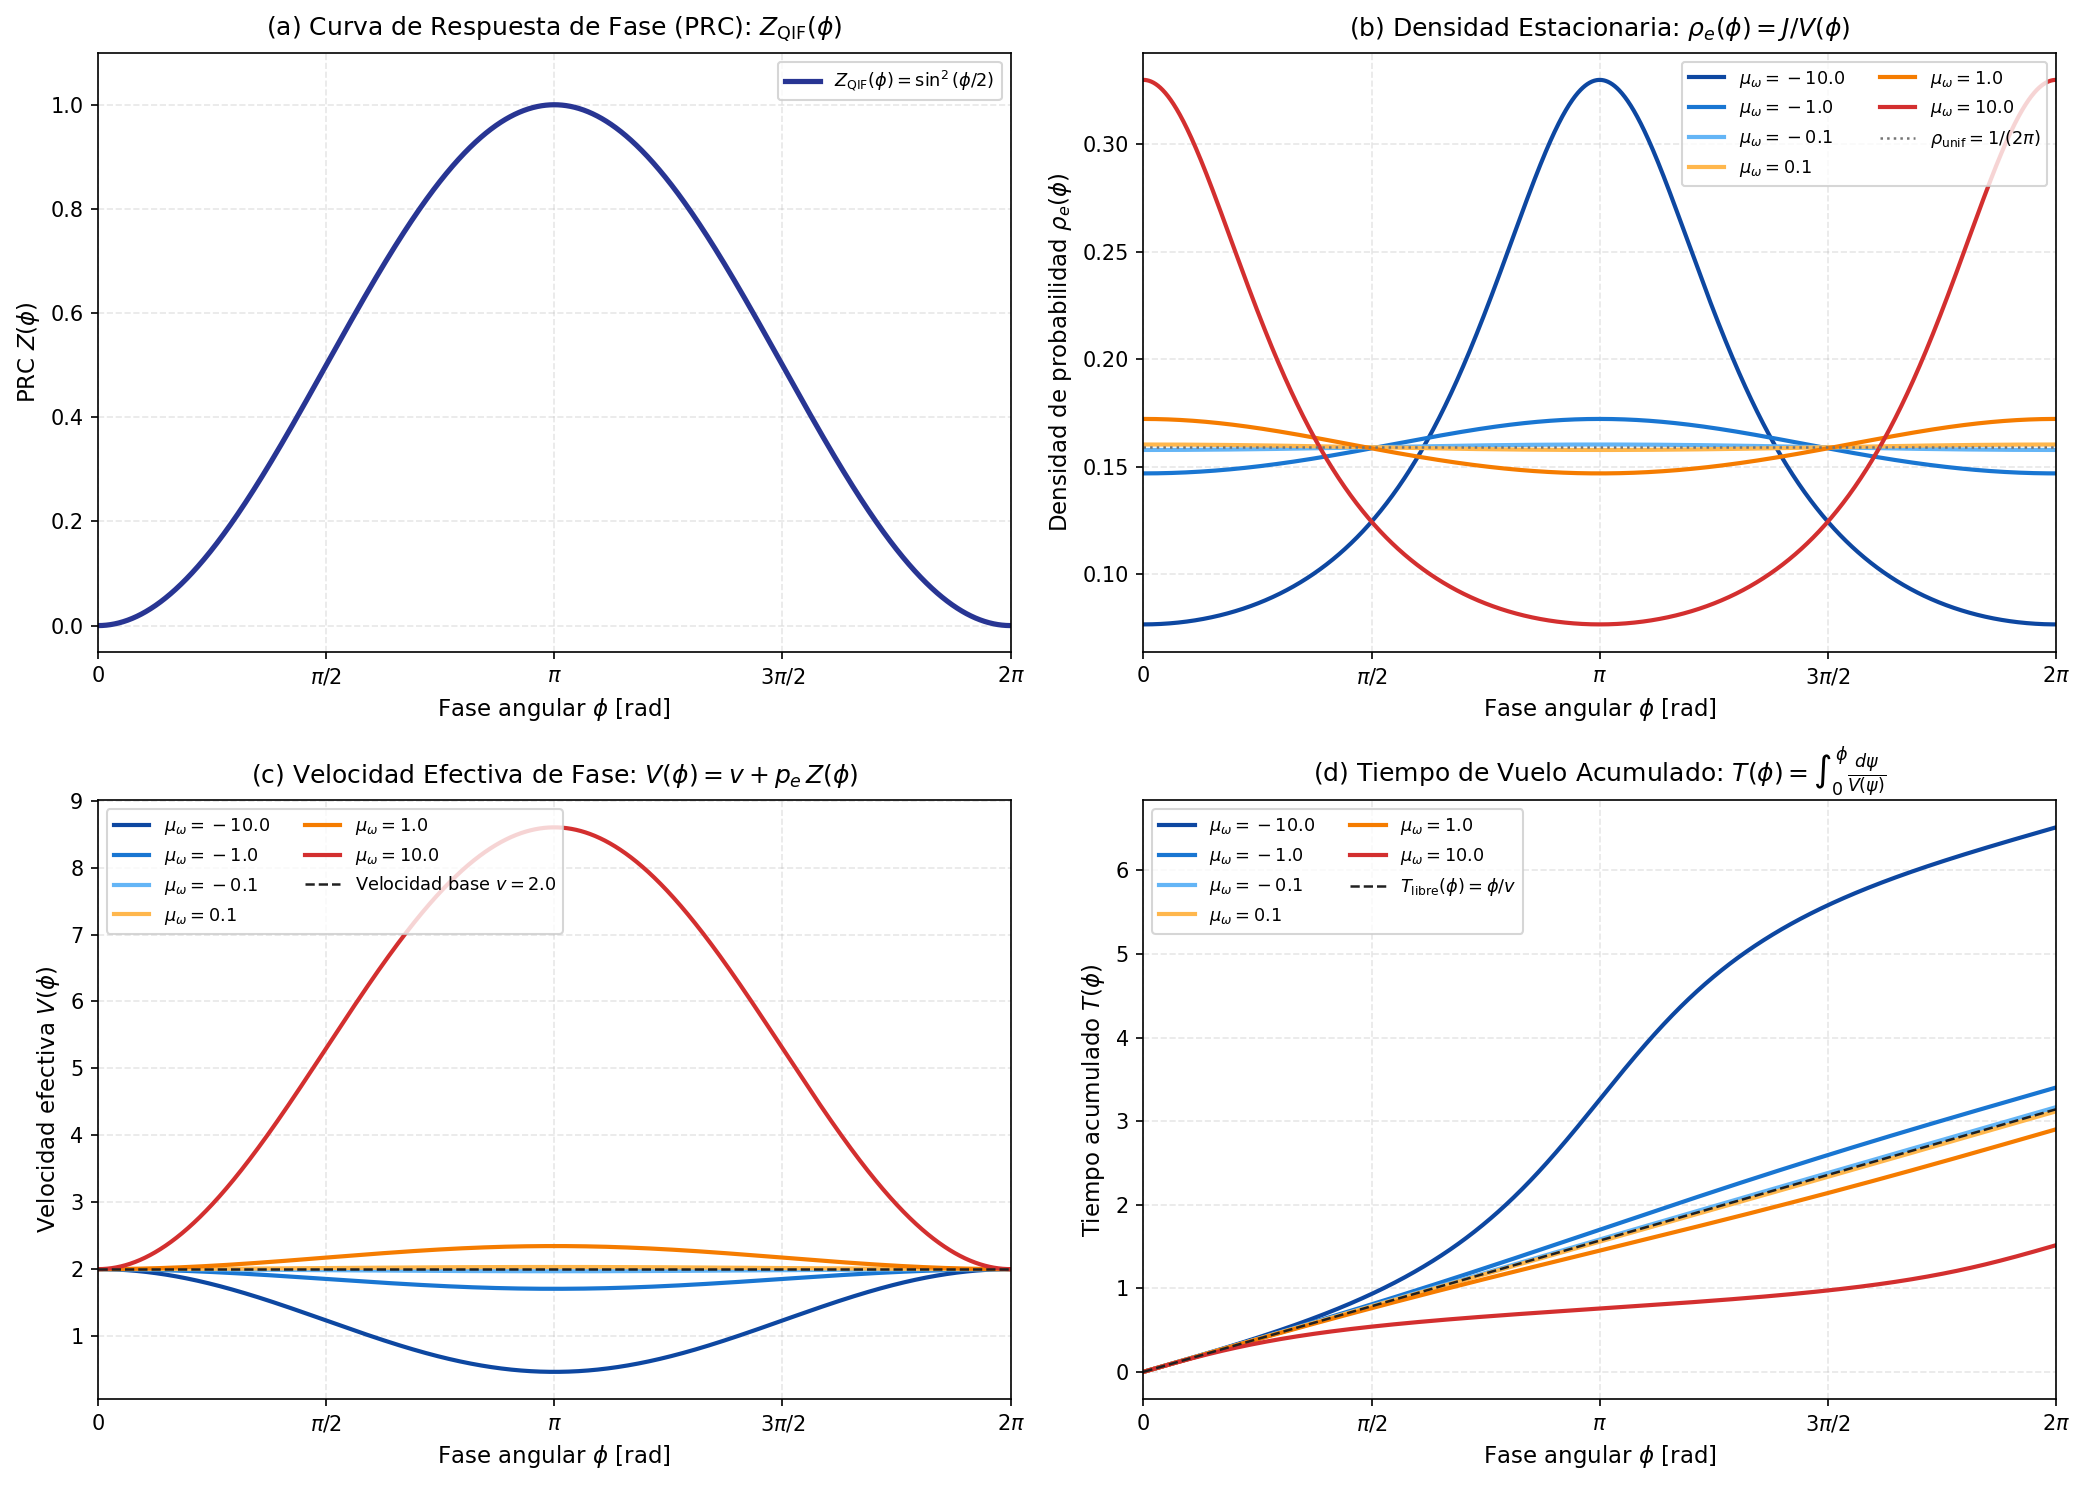

In [2]:
# ==============================================================================
# CARACTERIZACIÓN NUMÉRICA Y ANALÍTICA DEL ESTADO ESTACIONARIO - MODELO QIF
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. DEFINICIÓN DE LA CURVA DE RESPUESTA DE FASE (PRC) - MODELO QIF
# ------------------------------------------------------------------------------
def Z_QIF(phi):
    """
    Curva de Respuesta de Fase (PRC) microscópica para neuronas Quadratic Integrate-and-Fire (QIF).

    Definición canónica:
        Z_QIF(phi) = sin^2(phi / 2)  para phi in [0, 2*pi]

    Propiedades físicas y geométricas:
    - Se anula en el instante del disparo y reseteo: Z(0) = Z(2*pi) = 0.
    - Alcanza su valor máximo unitario en la mitad del ciclo: Z(pi) = 1.
    - Presenta simetría reflexiva respecto al ecuador: Z(phi) = Z(2*pi - phi).

    Parámetros:
    -----------
    phi : float o np.ndarray
        Fase o vector de fases en radianes en el intervalo [0, 2*pi].

    Devuelve:
    ---------
    float o np.ndarray : Amplitud de la respuesta de fase Z(phi).
    """
    return np.sin(0.5 * phi)**2


def Z_QIF_derivada(phi):
    """
    Derivada de la PRC Z_QIF con respecto a la fase phi.

    d/dphi [sin^2(phi / 2)] = sin(phi / 2) * cos(phi / 2) = 0.5 * sin(phi)

    Propiedad de antisimetría respecto a pi:
        Z'(phi) = - Z'(2*pi - phi)  con  Z'(0) = Z'(pi) = Z'(2*pi) = 0.
    """
    return 0.5 * np.sin(phi)


# ------------------------------------------------------------------------------
# 2. SOLUCIÓN ANALÍTICA CERRADA PARA J EN EL MODELO QIF (BENCHMARK TEÓRICO)
# ------------------------------------------------------------------------------
def J_analitico_QIF(mu_w, v=V_BASE):
    """
    Calcula el flujo de probabilidad estacionario exacto mediante la solución
    algebraica de la condición de normalización para Z(phi) = sin^2(phi/2):

        4*pi^2 * J^2 - v * mu_w * J - v^2 = 0

    Raíz positiva física:
        J = (v * mu_w + sqrt(v^2 * mu_w^2 + 16 * pi^2 * v^2)) / (8 * pi^2)

    Parámetros:
    -----------
    mu_w : float
        Constante de acoplamiento sináptico medio.
    v : float
        Velocidad intrínseca base (por defecto v = V_BASE = 2.0).

    Devuelve:
    ---------
    float : Valor exacto del flujo J.
    """
    discriminante = (v * mu_w)**2 + 16.0 * (np.pi**2) * (v**2)
    return (v * mu_w + np.sqrt(discriminante)) / (8.0 * np.pi**2)


# ------------------------------------------------------------------------------
# 3. RESOLUCIÓN NUMÉRICA AUTOCONSISTENTE DE J VÍA BRENTQ Y CUADRATURA GAUSSIANA
# ------------------------------------------------------------------------------
def resolver_J_QIF(mu_w, v=V_BASE):
    r"""
    Encuentra numéricamente el flujo estacionario J resolviendo la condición:
        J * \int_0^{2*pi} [1 / (v + mu_w * J * Z_QIF(phi))] dphi = 1

    Utiliza cuadratura adaptativa de Gauss-Kronrod (scipy.integrate.quad) y el
    algoritmo de Brent (scipy.optimize.root_scalar) sobre un intervalo seguro.

    Para evitar singularidades físicas en el régimen inhibidor (mu_w < 0), donde
    la velocidad efectiva podría anularse si J >= v / |mu_w|, se acota el bracket
    superior estrictamente por debajo de dicha asíntota singular.

    Parámetros:
    -----------
    mu_w : float
        Constante de acoplamiento sináptico medio.
    v : float
        Velocidad intrínseca base (fijada en 2.0).

    Devuelve:
    ---------
    float : Raíz numérica J que satisface la normalización unitaria.
    """
    # Función residual R(J) = J * integral [1 / V(phi)] dphi - 1 = 0
    def residual(J_cand):
        # Integración numérica del recíproco de la velocidad de fase
        integral_val, _ = integrate.quad(
            lambda phi: 1.0 / (v + mu_w * J_cand * Z_QIF(phi)),
            0.0,
            2.0 * np.pi,
            epsabs=1e-12,
            epsrel=1e-12
        )
        return J_cand * integral_val - 1.0

    # Caso particular desacoplado mu_w = 0: velocidad constante V(phi) = v
    if np.isclose(mu_w, 0.0):
        return v / (2.0 * np.pi)

    # Determinación robusta del intervalo de búsqueda (bracket)
    if mu_w < 0.0:
        # En acoplamiento inhibidor, la velocidad mínima ocurre en phi = pi:
        # V_min = v + mu_w * J. Para mantener V_min > 0, se requiere J < v / |mu_w|.
        J_singularidad = v / abs(mu_w)
        # Acotamos el límite superior al 99.99% de la asíntota singular
        bracket_inf = 1e-7
        bracket_sup = J_singularidad * (1.0 - 1e-4)
    else:
        # En acoplamiento excitador, V(phi) >= v > 0 para todo J > 0
        bracket_inf = 1e-7
        bracket_sup = max(5.0, 5.0 * mu_w)

    # Búsqueda de cero robusta mediante el método de Brent
    solucion = optimize.root_scalar(
        residual,
        bracket=[bracket_inf, bracket_sup],
        method='brentq',
        xtol=1e-12,
        rtol=1e-12
    )

    if not solucion.converged:
        raise RuntimeError(f"Error de convergencia en root_scalar para mu_w = {mu_w}")

    return float(solucion.root)


# ------------------------------------------------------------------------------
# 4. EVALUACIÓN Y TABULACIÓN PARA EL CONJUNTO DE ACOPLAMIENTOS ESPECIFICADO
# ------------------------------------------------------------------------------
# Valores de acoplamiento sináptico medio solicitados en el estudio
mu_valores = [-10.0, -1.0, -0.1, 0.1, 1.0, 10.0]

# Malla angular de alta resolución para la evaluación de perfiles y trayectorias
# Se usa un número impar de puntos (2001) para que el índice central caiga exactamente en phi = pi
N_PUNTOS_MALLA = 2001
phi_grid = np.linspace(0.0, 2.0 * np.pi, N_PUNTOS_MALLA)

# Estructuras de almacenamiento para resultados tabulares y curvas
registros_tabla = []
datos_graficos = {}

# Paleta cromática coordinada y accesible (de inhibición fuerte a excitación fuerte)
paleta_colores = [
    '#0D47A1',  # mu_w = -10.0 (Azul marino profundo)
    '#1976D2',  # mu_w = -1.0  (Azul medio)
    '#64B5F6',  # mu_w = -0.1  (Azul celeste)
    '#FFB74D',  # mu_w = +0.1  (Naranja claro)
    '#F57C00',  # mu_w = +1.0  (Naranja intenso)
    '#D32F2F',  # mu_w = +10.0 (Rojo bermellón)
]

print("Iniciando resolución autoconsistente para cada valor de mu_w con v = 2.0...")

for mu_w, color in zip(mu_valores, paleta_colores):
    # 1. Cálculo del flujo numérico y analítico
    J_num = resolver_J_QIF(mu_w, v=V_BASE)
    J_exact = J_analitico_QIF(mu_w, v=V_BASE)
    error_abs = abs(J_num - J_exact)

    # 2. Acoplamiento estacionario constante: p_e = mu_w * J
    p_e = mu_w * J_num

    # 3. Velocidad efectiva de fase: V(phi) = v + p_e * Z(phi)
    V_perfil = V_BASE + p_e * Z_QIF(phi_grid)

    # 4. Densidad de probabilidad estacionaria: rho_e(phi) = J / V(phi)
    rho_perfil = J_num / V_perfil

    # 5. Tiempo de vuelo acumulado: T(phi) = integral_0^phi [1 / V(phi')] dphi'
    # Empleamos la regla del trapecio acumulativa con paso de malla fino
    T_perfil = integrate.cumulative_trapezoid(1.0 / V_perfil, phi_grid, initial=0.0)

    # Valores exactos de tiempo de vuelo en los puntos de simetría (phi = pi y phi = 2*pi)
    # Calculados mediante cuadratura numérica adaptativa para máxima precisión
    T_pi, _ = integrate.quad(lambda phi_p: 1.0 / (V_BASE + p_e * Z_QIF(phi_p)), 0.0, np.pi, epsabs=1e-12, epsrel=1e-12)
    T_2pi = 1.0 / J_num  # Por definición de la normalización: T(2pi) = 1 / J

    # Almacenamiento para graficación
    datos_graficos[mu_w] = {
        'J': J_num,
        'p_e': p_e,
        'V': V_perfil,
        'rho': rho_perfil,
        'T': T_perfil,
        'color': color,
    }

    # Registro cuantitativo para DataFrame
    registros_tabla.append({
        r'$\mu_\omega$ [u.v.]': mu_w,
        r'$J_{\rm num}$ [1/u.t.]': J_num,
        r'$J_{\rm exacto}$ [1/u.t.]': J_exact,
        r'Error $|J - J_{\rm ex}|$ [1/u.t.]': error_abs,
        r'$p_e = \mu_\omega J$ [u.v./u.t.]': p_e,
        r'$\rho_e(0) = J/v$ [1/rad]': J_num / V_BASE,
        r'$T(\pi)$ [u.t.]': T_pi,
        r'$T(2\pi) = 1/J$ [u.t.]': T_2pi,
    })

# Conversión a DataFrame de Pandas
df_estacionario = pd.DataFrame(registros_tabla)

# Visualización formal y elegante de la tabla en Jupyter
print("\n" + "="*80)
print("TABLA 1: CARACTERIZACIÓN CUANTITATIVA DEL ESTADO ESTACIONARIO (v = 2.0)")
print("="*80)
display(df_estacionario.style.format({
    r'$J_{\rm num}$ [1/u.t.]': '{:.6f}',
    r'$J_{\rm exacto}$ [1/u.t.]': '{:.6f}',
    r'Error $|J - J_{\rm ex}|$ [1/u.t.]': '{:.2e}',
    r'$p_e = \mu_\omega J$ [u.v./u.t.]': '{:.6f}',
    r'$\rho_e(0) = J/v$ [1/rad]': '{:.6f}',
    r'$T(\pi)$ [u.t.]': '{:.6f}',
    r'$T(2\pi) = 1/J$ [u.t.]': '{:.6f}',
}))

# ------------------------------------------------------------------------------
# 5. VISUALIZACIÓN MULTIPANEL COMBINADA (4 SUBPLOTS)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=STYLE['dpi'])

# ------------------------------------------------------------------------------
# PANEL 1: Curva de Respuesta de Fase (PRC) Z(phi) vs phi
# ------------------------------------------------------------------------------
ax1 = axes[0, 0]
ax1.plot(phi_grid, Z_QIF(phi_grid), color='#283593', lw=STYLE['lw_main'] + 0.5, label=r'$Z_{\rm QIF}(\phi) = \sin^2(\phi/2)$')
ax1.set_title(r'(a) Curva de Respuesta de Fase (PRC): $Z_{\rm QIF}(\phi)$', fontsize=STYLE['fontsize_title'], pad=8)
ax1.set_xlabel(r'Fase angular $\phi$ [rad]', fontsize=STYLE['fontsize_label'])
ax1.set_ylabel(r'PRC $Z(\phi)$ [rad/u.v.]', fontsize=STYLE['fontsize_label'])
ax1.set_xlim(0.0, 2.0 * np.pi)
ax1.set_ylim(-0.05, 1.1)
ax1.set_xticks([0.0, 0.5 * np.pi, np.pi, 1.5 * np.pi, 2.0 * np.pi])
ax1.xaxis.set_major_formatter(pi_formatter)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.legend(loc='upper right', fontsize=STYLE['fontsize_legend'])

# ------------------------------------------------------------------------------
# PANEL 2: Densidad Estacionaria rho_e(phi) vs phi
# ------------------------------------------------------------------------------
ax2 = axes[0, 1]
for mu_w in mu_valores:
    dat = datos_graficos[mu_w]
    ax2.plot(phi_grid, dat['rho'], color=dat['color'], lw=STYLE['lw_main'], label=rf'$\mu_\omega = {mu_w}$ u.v.')
# Línea de referencia: distribución uniforme desacoplada rho = 1 / (2*pi)
ax2.axhline(1.0 / (2.0 * np.pi), color='#757575', linestyle=':', lw=STYLE['lw_aux'], label=r'$\rho_{\rm unif} = 1/(2\pi)$')
ax2.set_title(r'(b) Densidad Estacionaria: $\rho_e(\phi) = J / V(\phi)$', fontsize=STYLE['fontsize_title'], pad=8)
ax2.set_xlabel(r'Fase angular $\phi$ [rad]', fontsize=STYLE['fontsize_label'])
ax2.set_ylabel(r'Densidad de probabilidad $\rho_e(\phi)$ [1/rad]', fontsize=STYLE['fontsize_label'])
ax2.set_xlim(0.0, 2.0 * np.pi)
ax2.set_xticks([0.0, 0.5 * np.pi, np.pi, 1.5 * np.pi, 2.0 * np.pi])
ax2.xaxis.set_major_formatter(pi_formatter)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.legend(loc='upper right', fontsize=STYLE['fontsize_legend'], ncol=2)

# ------------------------------------------------------------------------------
# PANEL 3: Velocidad Efectiva V(phi) vs phi
# ------------------------------------------------------------------------------
ax3 = axes[1, 0]
for mu_w in mu_valores:
    dat = datos_graficos[mu_w]
    ax3.plot(phi_grid, dat['V'], color=dat['color'], lw=STYLE['lw_main'], label=rf'$\mu_\omega = {mu_w}$ u.v.')
# Línea de referencia: velocidad base constante v = 2.0
ax3.axhline(V_BASE, color='#212121', linestyle='--', lw=STYLE['lw_aux'], label=rf'Velocidad base $v = {V_BASE:.1f}$ rad/u.t.')
ax3.set_title(r'(c) Velocidad Efectiva de Fase: $V(\phi) = v + p_e \, Z(\phi)$', fontsize=STYLE['fontsize_title'], pad=8)
ax3.set_xlabel(r'Fase angular $\phi$ [rad]', fontsize=STYLE['fontsize_label'])
ax3.set_ylabel(r'Velocidad efectiva $V(\phi)$ [rad/u.t.]', fontsize=STYLE['fontsize_label'])
ax3.set_xlim(0.0, 2.0 * np.pi)
ax3.set_xticks([0.0, 0.5 * np.pi, np.pi, 1.5 * np.pi, 2.0 * np.pi])
ax3.xaxis.set_major_formatter(pi_formatter)
ax3.grid(True, alpha=0.3, linestyle='--')
ax3.legend(loc='upper left', fontsize=STYLE['fontsize_legend'], ncol=2)

# ------------------------------------------------------------------------------
# PANEL 4: Tiempo de Vuelo Acumulado T(phi) vs phi
# ------------------------------------------------------------------------------
ax4 = axes[1, 1]
for mu_w in mu_valores:
    dat = datos_graficos[mu_w]
    ax4.plot(phi_grid, dat['T'], color=dat['color'], lw=STYLE['lw_main'], label=rf'$\mu_\omega = {mu_w}$ u.v.')
# Línea de referencia: tiempo de vuelo de los osciladores libres desacoplados
ax4.plot(phi_grid, phi_grid / V_BASE, color='#212121', linestyle='--', lw=STYLE['lw_aux'], label=r'$T_{\rm libre}(\phi) = \phi / v$')
ax4.set_title(r'(d) Tiempo de Vuelo Acumulado: $T(\phi) = \int_0^\phi \frac{d\phi^{\prime}}{V(\phi^{\prime})}$', fontsize=STYLE['fontsize_title'], pad=8)
ax4.set_xlabel(r'Fase angular $\phi$ [rad]', fontsize=STYLE['fontsize_label'])
ax4.set_ylabel(r'Tiempo acumulado $T(\phi)$ [u.t.]', fontsize=STYLE['fontsize_label'])
ax4.set_xlim(0.0, 2.0 * np.pi)
ax4.set_xticks([0.0, 0.5 * np.pi, np.pi, 1.5 * np.pi, 2.0 * np.pi])
ax4.xaxis.set_major_formatter(pi_formatter)
ax4.grid(True, alpha=0.3, linestyle='--')
ax4.legend(loc='upper left', fontsize=STYLE['fontsize_legend'], ncol=2)

plt.tight_layout()
plt.show()


### Resolución Numérica de Autovalores Puramente Imaginarios ($s_n = i \nu_n$)

#### ¿Qué hace esta celda?
1. Resuelve numéricamente la ecuación trascendental de autovalores de estabilidad en el caso límite de modos colectivos puramente oscilatorios sin amortiguamiento ni amplificación ($\text{Re}(s_n) = \lambda_n = 0 \implies s_n = i \nu_n$, con $\nu_n \in \mathbb{R}^+$).
2. Determina el conjunto de frecuencias angulares de oscilación colectiva $\nu_n > 0$ que satisfacen el balance exacto entre el término inercial/cinemático y la fuerza de campo medio sináptico:
   $$
   \text{LHS}(\nu_n) = \text{RHS}(\nu_n)
   $$
   donde:
   $$
   \text{LHS}(\nu_n) = \sin\left[ \nu_n \, T(\pi) \right]
   $$
   $$
   \text{RHS}(\nu_n) = \mu_\omega \, J \, \nu_n \int_0^\pi \frac{Z(\phi')}{V^2(\phi')} \cos\left[ \nu_n \left\{ T(\phi') - T(\pi) \right\} \right] d\phi'
   $$
3. Identifica y clasifica las soluciones para cada acoplamiento $\mu_\omega \in \{-10.0, -1.0, -0.1, 0.1, 1.0, 10.0\}$ con velocidad intrínseca base fija $v = 2.0$.
4. Grafica las curvas $\text{LHS}(\nu)$ vs $\text{RHS}(\nu)$ en función de $\nu$ en una cuadrícula de 6 subplots, resaltando visualmente los puntos de intersección $\nu_n$.
5. Construye y presenta tablas cuantitativas (`pandas.DataFrame`) con las frecuencias angulares $\nu_n$ y sus respectivos períodos de oscilación colectivos asociados $T_{\rm modo} = \frac{2\pi}{\nu_n}$.

#### ¿Cómo lo hace?
* **Cálculo de funciones auxiliares:** Implementa `calcular_LHS(nu, T_pi)` y `calcular_RHS(nu, mu_w, J, v)`. La integral en $\text{RHS}(\nu)$ se calcula mediante cuadratura numérica adaptativa de alta precisión (`scipy.integrate.quad`), evaluando internamente el tiempo de vuelo $T(\phi')$ mediante su expresión analítica exacta para el modelo QIF:
  $$
  T(\phi') = \frac{2}{\sqrt{v(v + p_e)}} \arctan\left( \sqrt{\frac{v + p_e}{v}} \, \tan\left(\frac{\phi'}{2}\right) \right)
  $$
  lo que garantiza una evaluación computacionalmente veloz y libre de errores numéricos acumulados.
* **Escaneo sistemático y detección de ceros:** Evalúa la diferencia $f(\nu) = \text{LHS}(\nu) - \text{RHS}(\nu)$ sobre una malla densa de frecuencias $\nu \in [0.01, 15.0]$ [rad/u.t.]. Detecta automáticamente los intervalos donde ocurre un cambio de signo ($f(\nu_i) \cdot f(\nu_{i+1}) < 0$).
* **Refinamiento de raíces:** Aplica el método unidimensional de Brent (`scipy.optimize.root_scalar(method='brentq')`) dentro de cada intervalo de cambio de signo para refinar la raíz $\nu_n$ con tolerancia estricta ($10^{-10}$).
* **Visualización y tabulación:** Genera 6 paneles (uno por cada $\mu_\omega$) graficando $\text{LHS}(\nu)$ en trazo azul continuo y $\text{RHS}(\nu)$ en trazo rojo discontinuo, marcando los puntos de corte con marcadores verdes destacados y líneas verticales guía. Finalmente, estructura los resultados en un `DataFrame` de Pandas formateado formalmente con $\nu_n$ y $T_{\rm modo}$.

#### ¿Qué devuelve?
* Un panel combinado de 6 gráficos (subplots $3 \times 2$) donde se evidencia con claridad la intersección entre la curva sinusoidal $\text{LHS}(\nu)$ y la curva modulada $\text{RHS}(\nu)$ para cada $\mu_\omega$.
* Dos tablas estructuradas (`pandas.DataFrame`):
  1. **Tabla Resumen:** Con $\mu_\omega$, flujo $J$, acoplamiento $p_e$, tiempo $T(\pi)$, total de raíces encontradas en el rango, la frecuencia del modo fundamental $\nu_1$, su período colectivo $T_{\rm modo, 1}$, y la lista de raíces.
  2. **Tabla Detallada:** Con el desglose individual de cada modo $n$, su frecuencia $\nu_n$, su período $T_{\rm modo}$, y la verificación del residuo $|\text{LHS}(\nu_n) - \text{RHS}(\nu_n)| \approx 0$.


Buscando soluciones nu_n de la ecuacion trascendental para cada mu_w con v = 2.0...

TABLA 2: RESUMEN DE FRECUENCIAS ANGULARES nu_n Y PERÍODOS COLECTIVOS T_modo (v = 2.0)


,$\mu_\omega$,$J$,$p_e = \mu_\omega J$,$T(\pi)$,Total raíces,$\nu_1$ (fundamental) [rad/s],"$T_{\rm modo, 1}$ [s]",Raíces $\nu_n$ [rad/s]
0,-10.000000,0.153494,-1.534938,3.257461,15,1.570052,4.001897,"[1.5701, 1.9289, 2.8933, 3.8577, 4.8221, 5.7866, 6.751, 7.7154, 8.6799, 9.6443, 10.6087, 11.5732, 12.5376, 13.502, 14.4664]"
1,-1.000000,0.293986,-0.293986,1.700762,8,1.925101,3.263821,"[1.9251, 3.6943, 5.5415, 7.3887, 9.2358, 11.083, 12.9302, 14.7773]"
2,-0.100000,0.315787,-0.031579,1.583346,7,1.992090,3.154067,"[1.9921, 3.9683, 5.9524, 7.9366, 9.9207, 11.9049, 13.889]"
3,0.100000,0.320853,0.032085,1.558346,7,2.008005,3.129068,"[2.008, 4.032, 6.0479, 8.0639, 10.0799, 12.0959, 14.1119]"
4,1.000000,0.344646,0.344646,1.450762,6,2.084382,3.014412,"[2.0844, 4.331, 6.4964, 8.6619, 10.8274, 12.9929]"
5,10.000000,0.660100,6.600997,0.757461,3,3.255917,1.929774,"[3.2559, 8.2951, 12.4426]"


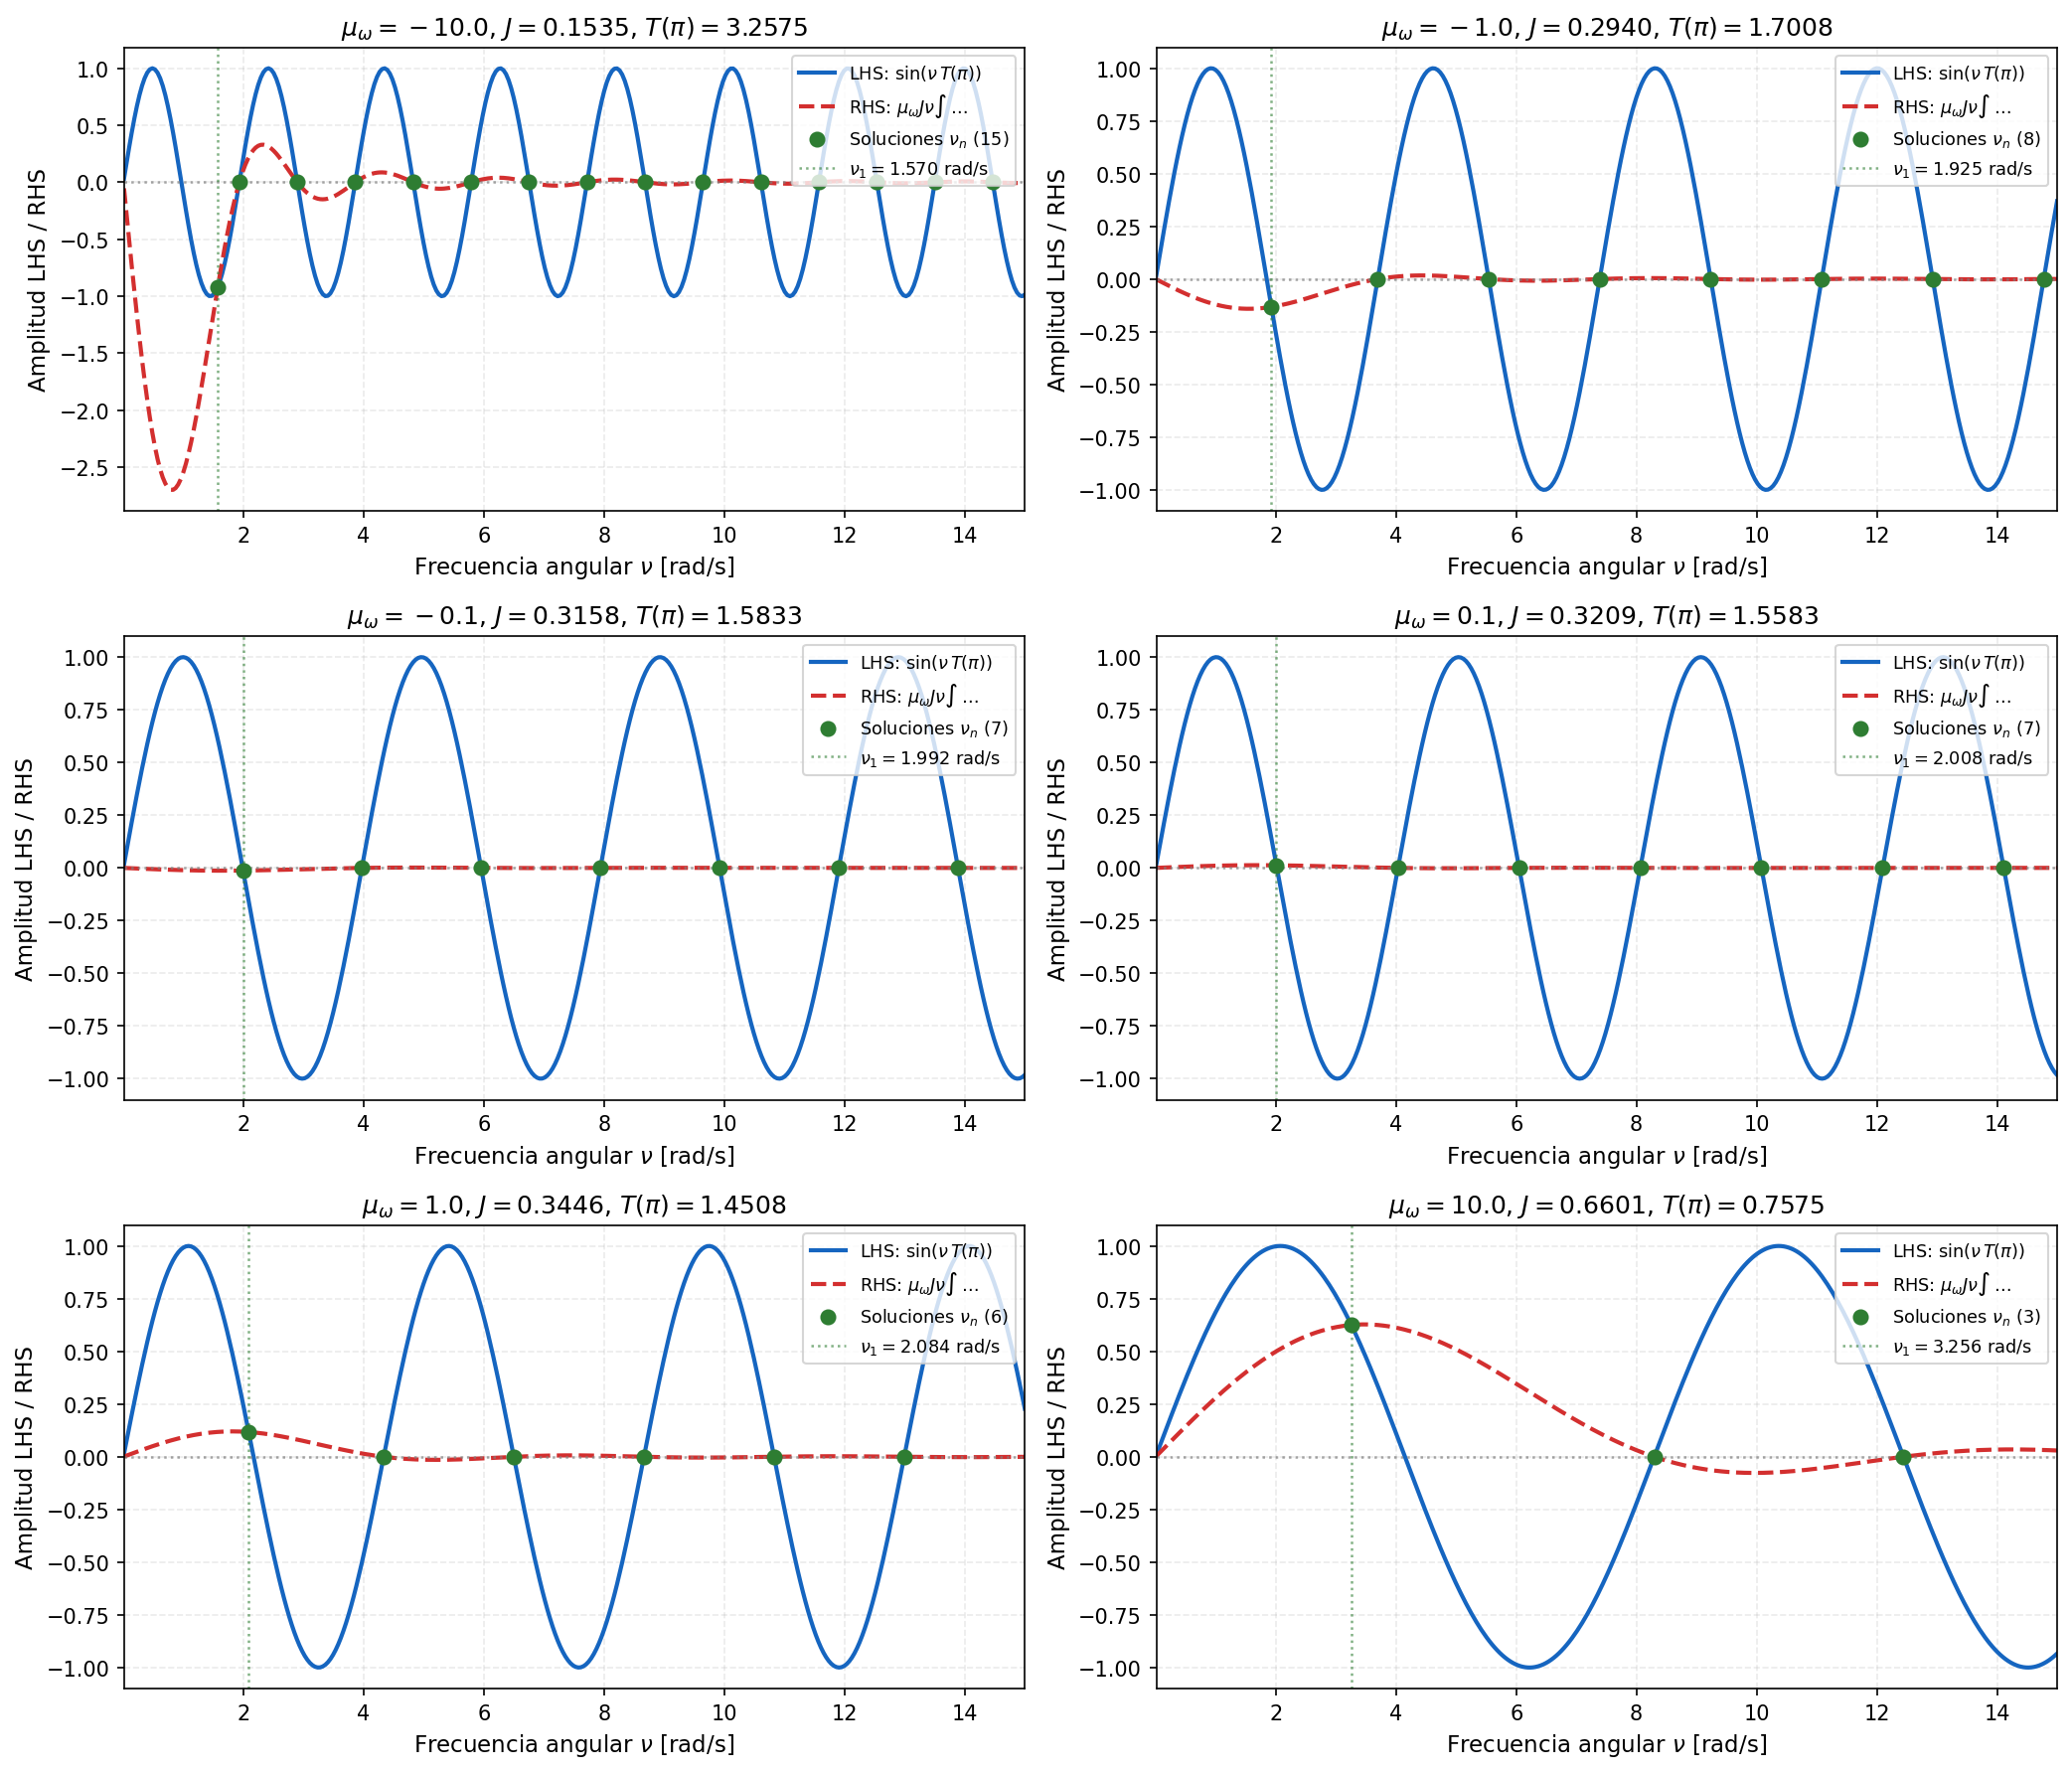

In [3]:
# ==============================================================================
# RESOLUCIÓN NUMÉRICA DE LA ECUACIÓN TRASCENDENTAL: AUTOVALORES IMAGINARIOS
# s_n = i * nu_n (nu_n in Real) - MODOS OSCILATORIOS COLECTIVOS
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. DEFINICIÓN DE FUNCIONES AUXILIARES: LHS(nu) Y RHS(nu)
# ------------------------------------------------------------------------------
def tiempo_vuelo_analitico_QIF(phi, mu_w, J, v=V_BASE):
    r"""
    Calcula de manera analítica y exacta el tiempo de vuelo acumulado:
        T(phi) = \int_0^phi [1 / (v + p_e * sin^2(phi'/2))] dphi'

    Solución cerrada:
        T(phi) = [2 / sqrt(v*(v + p_e))] * arctan( sqrt((v + p_e)/v) * tan(phi/2) )

    Parámetros:
    -----------
    phi : float o np.ndarray
        Fase angular en radianes en el intervalo [0, pi].
    mu_w : float
        Constante de acoplamiento sináptico medio.
    J : float
        Flujo de probabilidad estacionario.
    v : float
        Velocidad intrínseca base (fijada en 2.0).

    Devuelve:
    ---------
    float o np.ndarray : Tiempo acumulado T(phi).
    """
    pe = mu_w * J
    factor = 2.0 / np.sqrt(v * (v + pe))
    k = np.sqrt((v + pe) / v)
    T_pi = np.pi / np.sqrt(v * (v + pe))

    phi_arr = np.asarray(phi)
    res = np.zeros_like(phi_arr, dtype=float)

    # Manejo del punto phi = pi donde tan(phi/2) diverge
    mask_pi = np.isclose(phi_arr, np.pi)
    res[mask_pi] = T_pi
    not_pi = ~mask_pi
    res[not_pi] = factor * np.arctan(k * np.tan(0.5 * phi_arr[not_pi]))

    return float(res) if res.ndim == 0 else res


def calcular_LHS(nu, T_pi):
    r"""
    Lado izquierdo (LHS) de la ecuación trascendental para autovalores imaginarios:
        LHS(nu) = sin[ nu * T(pi) ]

    Parámetros:
    -----------
    nu : float o np.ndarray
        Frecuencia angular de oscilación [rad/u.t.].
    T_pi : float
        Tiempo de vuelo para recorrer medio ciclo (hasta phi = pi).

    Devuelve:
    ---------
    float o np.ndarray : Valor de LHS(nu).
    """
    return np.sin(nu * T_pi)


def calcular_RHS(nu, mu_w, J, v=V_BASE):
    r"""
    Lado derecho (RHS) de la ecuación trascendental para autovalores imaginarios:
        RHS(nu) = mu_w * J * nu * \int_0^pi { Z(phi') / V^2(phi') } * cos[ nu * { T(phi') - T(pi) } ] dphi'

    Utiliza cuadratura adaptativa de Gauss-Kronrod (scipy.integrate.quad) con alta precisión.

    Parámetros:
    -----------
    nu : float
        Frecuencia angular candidata [rad/u.t.].
    mu_w : float
        Constante de acoplamiento sináptico medio.
    J : float
        Flujo de probabilidad estacionario.
    v : float
        Velocidad intrínseca base (v = 2.0).

    Devuelve:
    ---------
    float : Amplitud del término de acoplamiento sináptico RHS(nu).
    """
    if np.isclose(nu, 0.0):
        return 0.0

    pe = mu_w * J
    factor_T = 2.0 / np.sqrt(v * (v + pe))
    k = np.sqrt((v + pe) / v)
    T_pi = np.pi / np.sqrt(v * (v + pe))

    # Integrando sobre phi' in [0, pi]
    def integrando(phi_p):
        # Velocidad efectiva V(phi')
        V_p = v + pe * Z_QIF(phi_p)
        # Tiempo de vuelo analítico T(phi')
        T_p = factor_T * np.arctan(k * np.tan(0.5 * phi_p))
        # Núcleo del integrando: [Z(phi') / V^2(phi')] * cos(nu * [T(phi') - T(pi)])
        return (Z_QIF(phi_p) / (V_p**2)) * np.cos(nu * (T_p - T_pi))

    # Cuadratura numérica adaptativa sobre [0, pi]
    integral_val, _ = integrate.quad(integrando, 0.0, np.pi, epsabs=1e-11, epsrel=1e-11)

    return mu_w * J * nu * integral_val


# ------------------------------------------------------------------------------
# 2. ESCANEO Y BÚSQUEDA SISTEMÁTICA DE RAÍCES nu_n EN (0, nu_max]
# ------------------------------------------------------------------------------
# Rango de escaneo de frecuencias angulares solicitado: nu in (0, 15.0] rad/u.t.
NU_MIN = 0.01
NU_MAX = 15.0
N_SCAN = 350
nu_malla = np.linspace(NU_MIN, NU_MAX, N_SCAN)

# Diccionario para almacenar curvas y soluciones por cada mu_w
soluciones_trascendental = {}
filas_resumen = []
filas_detalladas = []

print("Buscando soluciones nu_n de la ecuacion trascendental para cada mu_w con v = 2.0...")

for mu_w in mu_valores:
    # 1. Recuperamos J y los parámetros estacionarios calculados previamente
    J = J_analitico_QIF(mu_w, v=V_BASE)
    pe = mu_w * J
    T_pi = np.pi / np.sqrt(V_BASE * (V_BASE + pe))

    # 2. Evaluación de LHS y RHS sobre la malla de frecuencias
    lhs_curva = calcular_LHS(nu_malla, T_pi)
    rhs_curva = np.array([calcular_RHS(nu, mu_w, J, v=V_BASE) for nu in nu_malla])
    diff_curva = lhs_curva - rhs_curva

    # Función residual para el solver de alta precisión: f(nu) = LHS(nu) - RHS(nu) = 0
    def f_residuo(nu_cand):
        return calcular_LHS(nu_cand, T_pi) - calcular_RHS(nu_cand, mu_w, J, v=V_BASE)

    # 3. Detección de cambios de signo en la malla para delimitar brackets
    raices_encontradas = []
    for i in range(len(nu_malla) - 1):
        if diff_curva[i] * diff_curva[i+1] < 0.0:
            br_a = nu_malla[i]
            br_b = nu_malla[i+1]
            # Refinamiento mediante método de Brent
            sol_root = optimize.root_scalar(f_residuo, bracket=[br_a, br_b], method='brentq', xtol=1e-10)
            if sol_root.converged:
                raices_encontradas.append(float(sol_root.root))

    # 4. Almacenamiento de curvas y raíces
    soluciones_trascendental[mu_w] = {
        'J': J,
        'pe': pe,
        'T_pi': T_pi,
        'nu_malla': nu_malla,
        'lhs': lhs_curva,
        'rhs': rhs_curva,
        'raices': raices_encontradas,
    }

    # 5. Registro para tabla resumen
    nu_1 = raices_encontradas[0] if len(raices_encontradas) > 0 else np.nan
    T_modo_1 = (2.0 * np.pi / nu_1) if len(raices_encontradas) > 0 else np.nan
    filas_resumen.append({
        r'$\mu_\omega$ [u.v.]': mu_w,
        r'$J$ [1/u.t.]': J,
        r'$p_e = \mu_\omega J$ [u.v./u.t.]': pe,
        r'$T(\pi)$ [u.t.]': T_pi,
        r'Total raíces': len(raices_encontradas),
        r'$\nu_1$ (fundamental) [rad/u.t.]': nu_1,
        r'$T_{\rm modo, 1}$ [u.t.]': T_modo_1,
        r'Raíces $\nu_n$ [rad/u.t.]': [round(r, 4) for r in raices_encontradas],
    })

    # 6. Registros para tabla detallada por modo
    for idx_m, r in enumerate(raices_encontradas, 1):
        filas_detalladas.append({
            r'$\mu_\omega$ [u.v.]': mu_w,
            r'Modo $n$': idx_m,
            r'$\nu_n$ [rad/u.t.]': r,
            r'$T_{\rm modo} = 2\pi/\nu_n$ [u.t.]': 2.0 * np.pi / r,
            r'LHS($\nu_n$)': calcular_LHS(r, T_pi),
            r'RHS($\nu_n$)': calcular_RHS(r, mu_w, J, v=V_BASE),
            r'|LHS - RHS|': abs(calcular_LHS(r, T_pi) - calcular_RHS(r, mu_w, J, v=V_BASE)),
        })

# Construcción de DataFrames de Pandas
df_resumen_modos = pd.DataFrame(filas_resumen)
df_detallado_modos = pd.DataFrame(filas_detalladas)

# Visualización formal de las tablas
print("\n" + "="*95)
print("TABLA 2: RESUMEN DE FRECUENCIAS ANGULARES nu_n Y PERÍODOS COLECTIVOS T_modo (v = 2.0)")
print("="*95)
display(df_resumen_modos.style.format({
    r'$J$ [1/u.t.]': '{:.6f}',
    r'$p_e = \mu_\omega J$ [u.v./u.t.]': '{:.6f}',
    r'$T(\pi)$ [u.t.]': '{:.6f}',
    r'$\nu_1$ (fundamental) [rad/u.t.]': '{:.6f}',
    r'$T_{\rm modo, 1}$ [u.t.]': '{:.6f}',
}))

# ------------------------------------------------------------------------------
# 3. VISUALIZACIÓN GRÁFICA MULTIPANEL: INTERSECCIONES LHS(nu) vs RHS(nu)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(3, 2, figsize=(14, 12), dpi=STYLE['dpi'])
axes = axes.flatten()

for idx, mu_w in enumerate(mu_valores):
    ax = axes[idx]
    sol = soluciones_trascendental[mu_w]

    # Curva LHS(nu) = sin(nu * T(pi))
    ax.plot(sol['nu_malla'], sol['lhs'], color='#1565C0', lw=STYLE['lw_main'], label=r'LHS: $\sin(\nu \, T(\pi))$')

    # Curva RHS(nu) = mu_w * J * nu * \int ...
    ax.plot(sol['nu_malla'], sol['rhs'], color='#D32F2F', lw=STYLE['lw_main'], linestyle='--', label=r'RHS: $\mu_\omega J \nu \int \dots$')

    # Línea horizontal cero de referencia
    ax.axhline(0.0, color='gray', linestyle=':', lw=STYLE['lw_aux'], alpha=0.7)

    # Marcado explícito de los puntos de intersección encontrados (soluciones nu_n)
    raices = sol['raices']
    if len(raices) > 0:
        lhs_raices = [calcular_LHS(r, sol['T_pi']) for r in raices]
        ax.scatter(raices, lhs_raices, color='#2E7D32', s=45, zorder=5, label=f'Soluciones $\\nu_n$ ({len(raices)})')

        # Línea guía vertical y anotación para el modo fundamental nu_1
        nu_fund = raices[0]
        ax.axvline(nu_fund, color='#2E7D32', linestyle=':', lw=1.2, alpha=0.6, label=rf'$\nu_1 = {nu_fund:.3f}$ rad/u.t.')

    # Configuración de títulos, ejes y formato
    ax.set_title(rf'$\mu_\omega = {mu_w}$ u.v., $J = {sol["J"]:.4f}$ u.t.$^{{-1}}$, $T(\pi) = {sol["T_pi"]:.4f}$ u.t.', fontsize=STYLE['fontsize_title'], pad=6)
    ax.set_xlabel(r'Frecuencia angular $\nu$ [rad/u.t.]', fontsize=STYLE['fontsize_label'])
    ax.set_ylabel(r'Amplitud LHS / RHS [adim.]', fontsize=STYLE['fontsize_label'])
    ax.set_xlim(NU_MIN, NU_MAX)
    ax.grid(True, alpha=0.25, linestyle='--')
    ax.legend(loc='upper right', fontsize=STYLE['fontsize_legend'])

plt.tight_layout()
plt.show()


---

### 2. Extensión del Análisis a la PRC Triangular Simétrica (Modelo Tent)

#### 2.1. Definición de la PRC $Z_{\rm tent}(\phi)$
Consideramos ahora la PRC lineal a trozos (*tent* o "tienda de campaña"), cuyo vértice se ubica en la fracción `_TENT_FRAC` del ciclo. Para que la PRC pertenezca a la clase simétrica estudiada en la Sección 1.5 fijamos **`_TENT_FRAC = 0.5`**, de modo que el vértice queda exactamente en $\phi_1 = \pi$ y ambas pendientes coinciden en módulo, $A = B = 1/\pi$:
$$
Z_{\rm tent}(\phi) =
\begin{cases}
\dfrac{\phi}{\pi}, & 0 \le \phi \le \pi \\[2mm]
\dfrac{2\pi - \phi}{\pi}, & \pi \le \phi \le 2\pi
\end{cases}
$$

Propiedades relevantes:
* Anulación en el disparo: $Z_{\rm tent}(0) = Z_{\rm tent}(2\pi) = 0$, por lo que vale $p_e = \mu_\omega J$ y $\rho_e(0) = J/v$.
* Máximo unitario en el vértice: $Z_{\rm tent}(\pi) = 1$ (misma amplitud que $Z_{\rm QIF}$).
* Simetría reflexiva exacta: $Z_{\rm tent}(2\pi - \phi) = Z_{\rm tent}(\phi)$.
* **Punto de quiebre en $\phi = \pi$:** $Z_{\rm tent}$ es continua pero su derivada salta de $+1/\pi$ a $-1/\pi$. Por eso toda integral numérica sobre $[0, 2\pi]$ se parte explícitamente en $\phi = \pi$, mientras que las integrales de la ecuación trascendental, que van sólo sobre $[0, \pi]$, tienen el quiebre en el extremo del intervalo y no se ven afectadas.

> **Nota:** en `ConectividadGenericaDinamicaRedGenerica.ipynb` la tienda está definida actualmente con `_TENT_FRAC = 0.6` (versión asimétrica, vértice en $1.2\pi$), que **no** satisface la simetría requerida. Todo el análisis de esta sección corresponde a la versión simétrica `_TENT_FRAC = 0.5`.

---

#### 2.2. Normalización Analítica de $\rho_e(\phi)$
La densidad estacionaria tiene la forma general
$$
\rho_e(\phi) = \frac{J}{v + \mu_\omega J \, Z_{\rm tent}(\phi)} = \frac{\rho_e(0)}{1 + \mu_\omega \, \rho_e(0) \, [Z_{\rm tent}(\phi) - Z_{\rm tent}(0)]}
$$
Como ambas ramas de $Z_{\rm tent}$ son lineales, cada tramo contribuye con un logaritmo:
$$
\int_0^{2\pi} \rho_e(\phi)\, d\phi = \frac{1}{\mu_\omega}\left(\frac{1}{A} + \frac{1}{B}\right)\ln\left[1 + \mu_\omega \rho_e(0)\right] = \frac{2\pi}{\mu_\omega}\ln\left[1 + \mu_\omega \rho_e(0)\right] = 1
$$
de donde se obtienen las expresiones cerradas:
$$
\rho_e(0) = \frac{e^{\mu_\omega / 2\pi} - 1}{\mu_\omega}, \qquad J_{\rm exacto} = v \, \rho_e(0) = \frac{v\left(e^{\mu_\omega/2\pi} - 1\right)}{\mu_\omega}, \qquad p_e = \mu_\omega J = v\left(e^{\mu_\omega/2\pi} - 1\right)
$$
(con el límite desacoplado $\rho_e(0) \to 1/(2\pi)$ cuando $\mu_\omega \to 0$).

---

#### 2.3. Condición de No-Bloqueo de Fases
El estado estacionario es físico sólo si la velocidad efectiva no se anula en ningún punto del ciclo, es decir:
$$
1 + \mu_\omega \, \rho_e(0)\,[Z_{\rm tent}(\phi) - Z_{\rm tent}(0)] > 0 \quad \forall \phi \in [0, 2\pi]
$$
Como $0 \le Z_{\rm tent} \le 1$, el mínimo de esta cantidad es $\min\{1,\, 1 + \mu_\omega \rho_e(0)\}$, y por la normalización:
$$
1 + \mu_\omega \, \rho_e(0) = e^{\mu_\omega / 2\pi} > 0 \quad \text{para todo } \mu_\omega
$$
Es decir, **para la tienda simétrica la condición de no-bloqueo se satisface automáticamente para cualquier acoplamiento**, a diferencia de una cota dura sobre $J$. Sin embargo, en el régimen inhibidor el margen decrece exponencialmente con $|\mu_\omega|$: para $\mu_\omega = -10$ ya es $V(\pi)/v = e^{-10/2\pi} \approx 0.20$, y la raíz $J$ queda tanto más cerca de la asíntota $J = v/|\mu_\omega|$ cuanto más fuerte es la inhibición. Para que el cálculo numérico sea robusto:
* Se resuelve la normalización parametrizando $J$ mediante $u = \ln\left[1 + \mu_\omega J / v\right] = \ln[V_{\rm min}/v]$ para $\mu_\omega<0$ (es decir $J = v\,(e^{u} - 1)/\mu_\omega$), de modo que **cualquier** $u$ de la búsqueda produce un estado sin bloqueo por construcción.
* Las integrales de la ecuación trascendental se calculan en la variable tiempo de vuelo en lugar de $\phi'$, eliminando el máximo de $1/V^2$ en $\phi' = \pi$ (ver 2.5).

---

#### 2.4. Tiempo de Vuelo Analítico
En la primera mitad del ciclo $V(\phi) = v + p_e \, \phi/\pi$, y la integral del tiempo de vuelo es elemental:
$$
T(\phi) = \int_0^\phi \frac{d\phi'}{v + p_e \phi'/\pi} = \frac{\pi}{p_e}\ln\left(1 + \frac{p_e \, \phi}{\pi v}\right), \qquad 0 \le \phi \le \pi
$$
y por simetría $T(\phi) = 2T(\pi) - T(2\pi - \phi)$ para $\pi \le \phi \le 2\pi$. Evaluando en el vértice:
$$
T(\pi) = \frac{\pi}{p_e}\ln\left(1 + \frac{p_e}{v}\right) = \frac{\pi}{p_e}\cdot\frac{\mu_\omega}{2\pi} = \frac{1}{2J}
$$
lo que verifica explícitamente la identidad de simetría $T(\pi) = T(2\pi)/2$ de la Sección 1.4. La relación es invertible:
$$
\phi(T) = \frac{\pi v}{p_e}\left(e^{p_e T/\pi} - 1\right), \qquad V(\phi(T)) = v \, e^{p_e T/\pi}
$$

---

#### 2.5. Ecuación Trascendental para $s_n = i\nu_n$: Cambio de Variable y Solución Cerrada
Partimos de la misma ecuación de la Sección 1.5:
$$
\sin\left[\nu_n T(\pi)\right] = \mu_\omega J \, \nu_n \int_0^\pi \frac{Z(\phi')}{V^2(\phi')}\cos\left[\nu_n\{T(\phi') - T(\pi)\}\right] d\phi'
$$
Usando $d\phi' = V(\phi')\, dT$ la integral pasa a la variable tiempo de vuelo $T \in [0, T(\pi)]$:
$$
\int_0^\pi \frac{Z(\phi')}{V^2(\phi')}\cos[\dots]\, d\phi' = \int_0^{T(\pi)} \frac{Z(\phi(T))}{V(\phi(T))}\cos\left[\nu\,(T - T(\pi))\right] dT
$$
Este cambio de variable es exacto y numéricamente ventajoso: el integrando en $T$ es suave y no presenta el máximo de $1/V^2$ en $\phi' \to \pi$, que se vuelve arbitrariamente angosto al aumentar la inhibición. Para la tienda, además, $Z/V = \frac{1}{p_e}\left(1 - e^{-aT}\right)$ con $a \equiv p_e/\pi$, y la integral es elemental. Sustituyendo y usando $p_e = \mu_\omega J$:
$$
\text{RHS}(\nu) = \sin\left[\nu T(\pi)\right] - \frac{\nu\left[a\cos(\nu T(\pi)) + \nu \sin(\nu T(\pi)) - a\, e^{-a T(\pi)}\right]}{a^2 + \nu^2}, \qquad e^{-aT(\pi)} = \frac{v}{v + p_e} = e^{-\mu_\omega/2\pi}
$$
Por lo tanto, para $\nu \neq 0$, la condición $\text{LHS} = \text{RHS}$ se reduce a la ecuación trascendental cerrada:
$$
\boxed{\;a\cos\left[\nu T(\pi)\right] + \nu\sin\left[\nu T(\pi)\right] = a\, e^{-\mu_\omega/2\pi}, \qquad a = \frac{p_e}{\pi}, \quad T(\pi) = \frac{1}{2J}\;}
$$
En las celdas siguientes se resuelve la ecuación **numéricamente** (cuadratura en la variable $T$, como en el caso QIF) y se usa la forma cerrada como **benchmark analítico** de validación, del mismo modo que $J_{\rm exacto}$ valida a $J_{\rm num}$.

### Caracterización del Estado Estacionario para el Modelo Tent Simétrico

#### ¿Qué hace esta celda?
1. Implementa la PRC triangular simétrica $Z_{\rm tent}(\phi)$ con **`_TENT_FRAC = 0.5`** (vértice en $\phi = \pi$, pendientes $A = B = 1/\pi$) y verifica numéricamente sus condiciones de contorno $Z(0) = Z(2\pi) = 0$, $Z(\pi) = 1$ y su simetría $Z(2\pi - \phi) = Z(\phi)$.
2. Resuelve numéricamente la condición autoconsistente de normalización para el flujo estacionario $J$ para cada acoplamiento $\mu_\omega \in \{-10, -1, -0.1, 0.1, 1, 10\}$ (el mismo conjunto estudiado para el QIF), con $v = 2.0$.
3. Contrasta $J_{\rm num}$ contra la solución analítica exacta $J_{\rm exacto} = v\,(e^{\mu_\omega/2\pi} - 1)/\mu_\omega$.
4. Verifica explícitamente la condición de no-bloqueo $1 + \mu_\omega \rho_e(0)[Z_{\rm tent}(\phi) - Z_{\rm tent}(0)] > 0$ y la normalización $\int_0^{2\pi}\rho_e(\phi)\,d\phi = 1$.
5. Obtiene los perfiles de $\rho_e(\phi)$, $V(\phi)$ y $T(\phi)$, y los presenta en una tabla y en una figura de 4 paneles análoga a la del QIF.

#### ¿Cómo lo hace?
* **PRC:** `Z_tent` se implementa con `np.where` sobre las dos ramas lineales; `Z_tent_derivada` devuelve las pendientes laterales $\pm 1/\pi$ (asignando el promedio lateral $0$ en el quiebre $\phi = \pi$).
* **Resolución de $J$ sin bloqueo:** en lugar de buscar $J$ directamente con un bracket acotado por la asíntota $J = v/|\mu_\omega|$ (cuya distancia a la raíz se reduce exponencialmente al aumentar la inhibición), se parametriza $J(u) = v\,(e^{u} - 1)/\mu_\omega$ con $u = \ln[1 + p_e/v]$. El signo de $u$ coincide con el de $\mu_\omega$ (para que $J > 0$) y el extremo exterior del bracket se obtiene duplicando $|u|$ desde $1$ hasta que el residuo cambia de signo (con tope $|u| \le 30$), con lo cual **toda** evaluación del residuo corresponde a una velocidad $V(\phi) \ge v\,\min(1, e^{u}) > 0$. El residuo $R(u) = J(u)\int_0^{2\pi}\frac{d\phi}{v + \mu_\omega J(u) Z_{\rm tent}(\phi)} - 1$ se integra con `scipy.integrate.quad` partiendo el intervalo en el quiebre (`points=[π]`) y su cero se halla con Brent (`brentq`).
* **Tiempo de vuelo:** se usa la expresión analítica $T(\phi) = \frac{\pi}{p_e}\ln\left(1 + \frac{p_e\phi}{\pi v}\right)$ en $[0,\pi]$ y su reflexión simétrica en $[\pi, 2\pi]$. A diferencia del QIF, aquí no se usa la regla del trapecio acumulativa, ya que se dispone de la expresión exacta (que además no pierde precisión en el quiebre $\phi = \pi$). El valor $T(\pi)$ se verifica además por cuadratura adaptativa y contra $1/(2J)$.
* **Visualización:** misma estética que el QIF (`STYLE`, `pi_formatter`, misma paleta divergente azul → rojo para los 6 valores de $\mu_\omega$), con la línea vertical que marca el quiebre de $Z_{\rm tent}$ en $\phi = \pi$.

#### ¿Qué devuelve?
* Una tabla (`pandas.DataFrame`) con $\mu_\omega$, $J_{\rm num}$, $J_{\rm exacto}$, el error absoluto, $p_e$, $\rho_e(0)$, el margen de no-bloqueo $\min_\phi\{1 + \mu_\omega \rho_e(0) Z_{\rm tent}\}$, la normalización numérica $\int\rho_e$, $T(\pi)$ y $T(2\pi) = 1/J$.
* Un gráfico de 4 paneles: **(a)** $Z_{\rm tent}(\phi)$, **(b)** $\rho_e(\phi)$, **(c)** $V(\phi)$ y **(d)** $T(\phi)$ para todos los $\mu_\omega$.

Iniciando resolución autoconsistente (modelo tent simétrico) para cada mu_w con v = 2.0...

TABLA 3: ESTADO ESTACIONARIO - MODELO TENT SIMÉTRICO (_TENT_FRAC = 0.5, v = 2.0)


,$\mu_\omega$,$J_{\rm num}$,$J_{\rm exacto}$,Error $|J - J_{\rm ex}|$,$p_e = \mu_\omega J$,$\rho_e(0) = J/v$,$\min_\phi[1 + \mu_\omega \rho_e(0) Z]$,"$\min\{1, e^{\mu_\omega/2\pi}\}$","$\int \rho_e \, d\phi$",$T(\pi)$ (quad),$T(\pi)$ (analítico),$T(2\pi) = 1/J$
0,-10.000000,1.592780e-01,1.592780e-01,0.00e+00,-1.592780,7.963901e-02,2.0361e-01,2.0361e-01,1.0000000000,3.139165,3.139165,6.278330
1,-1.000000,2.942716e-01,2.942716e-01,5.55e-17,-0.294272,1.471358e-01,8.5286e-01,8.5286e-01,1.0000000000,1.699111,1.699111,3.398221
2,-0.100000,3.157902e-01,3.157902e-01,5.55e-17,-0.031579,1.578951e-01,9.8421e-01,9.8421e-01,1.0000000000,1.583329,1.583329,3.166659
3,0.100000,3.208564e-01,3.208564e-01,5.55e-17,0.032086,1.604282e-01,1.0000e+00,1.0000e+00,1.0000000000,1.558329,1.558329,3.116659
4,1.000000,3.450392e-01,3.450392e-01,1.11e-16,0.345039,1.725196e-01,1.0000e+00,1.0000e+00,1.0000000000,1.449111,1.449111,2.898221
5,10.000000,7.822706e-01,7.822706e-01,1.11e-16,7.822706,3.911353e-01,1.0000e+00,1.0000e+00,1.0000000000,0.639165,0.639165,1.278330


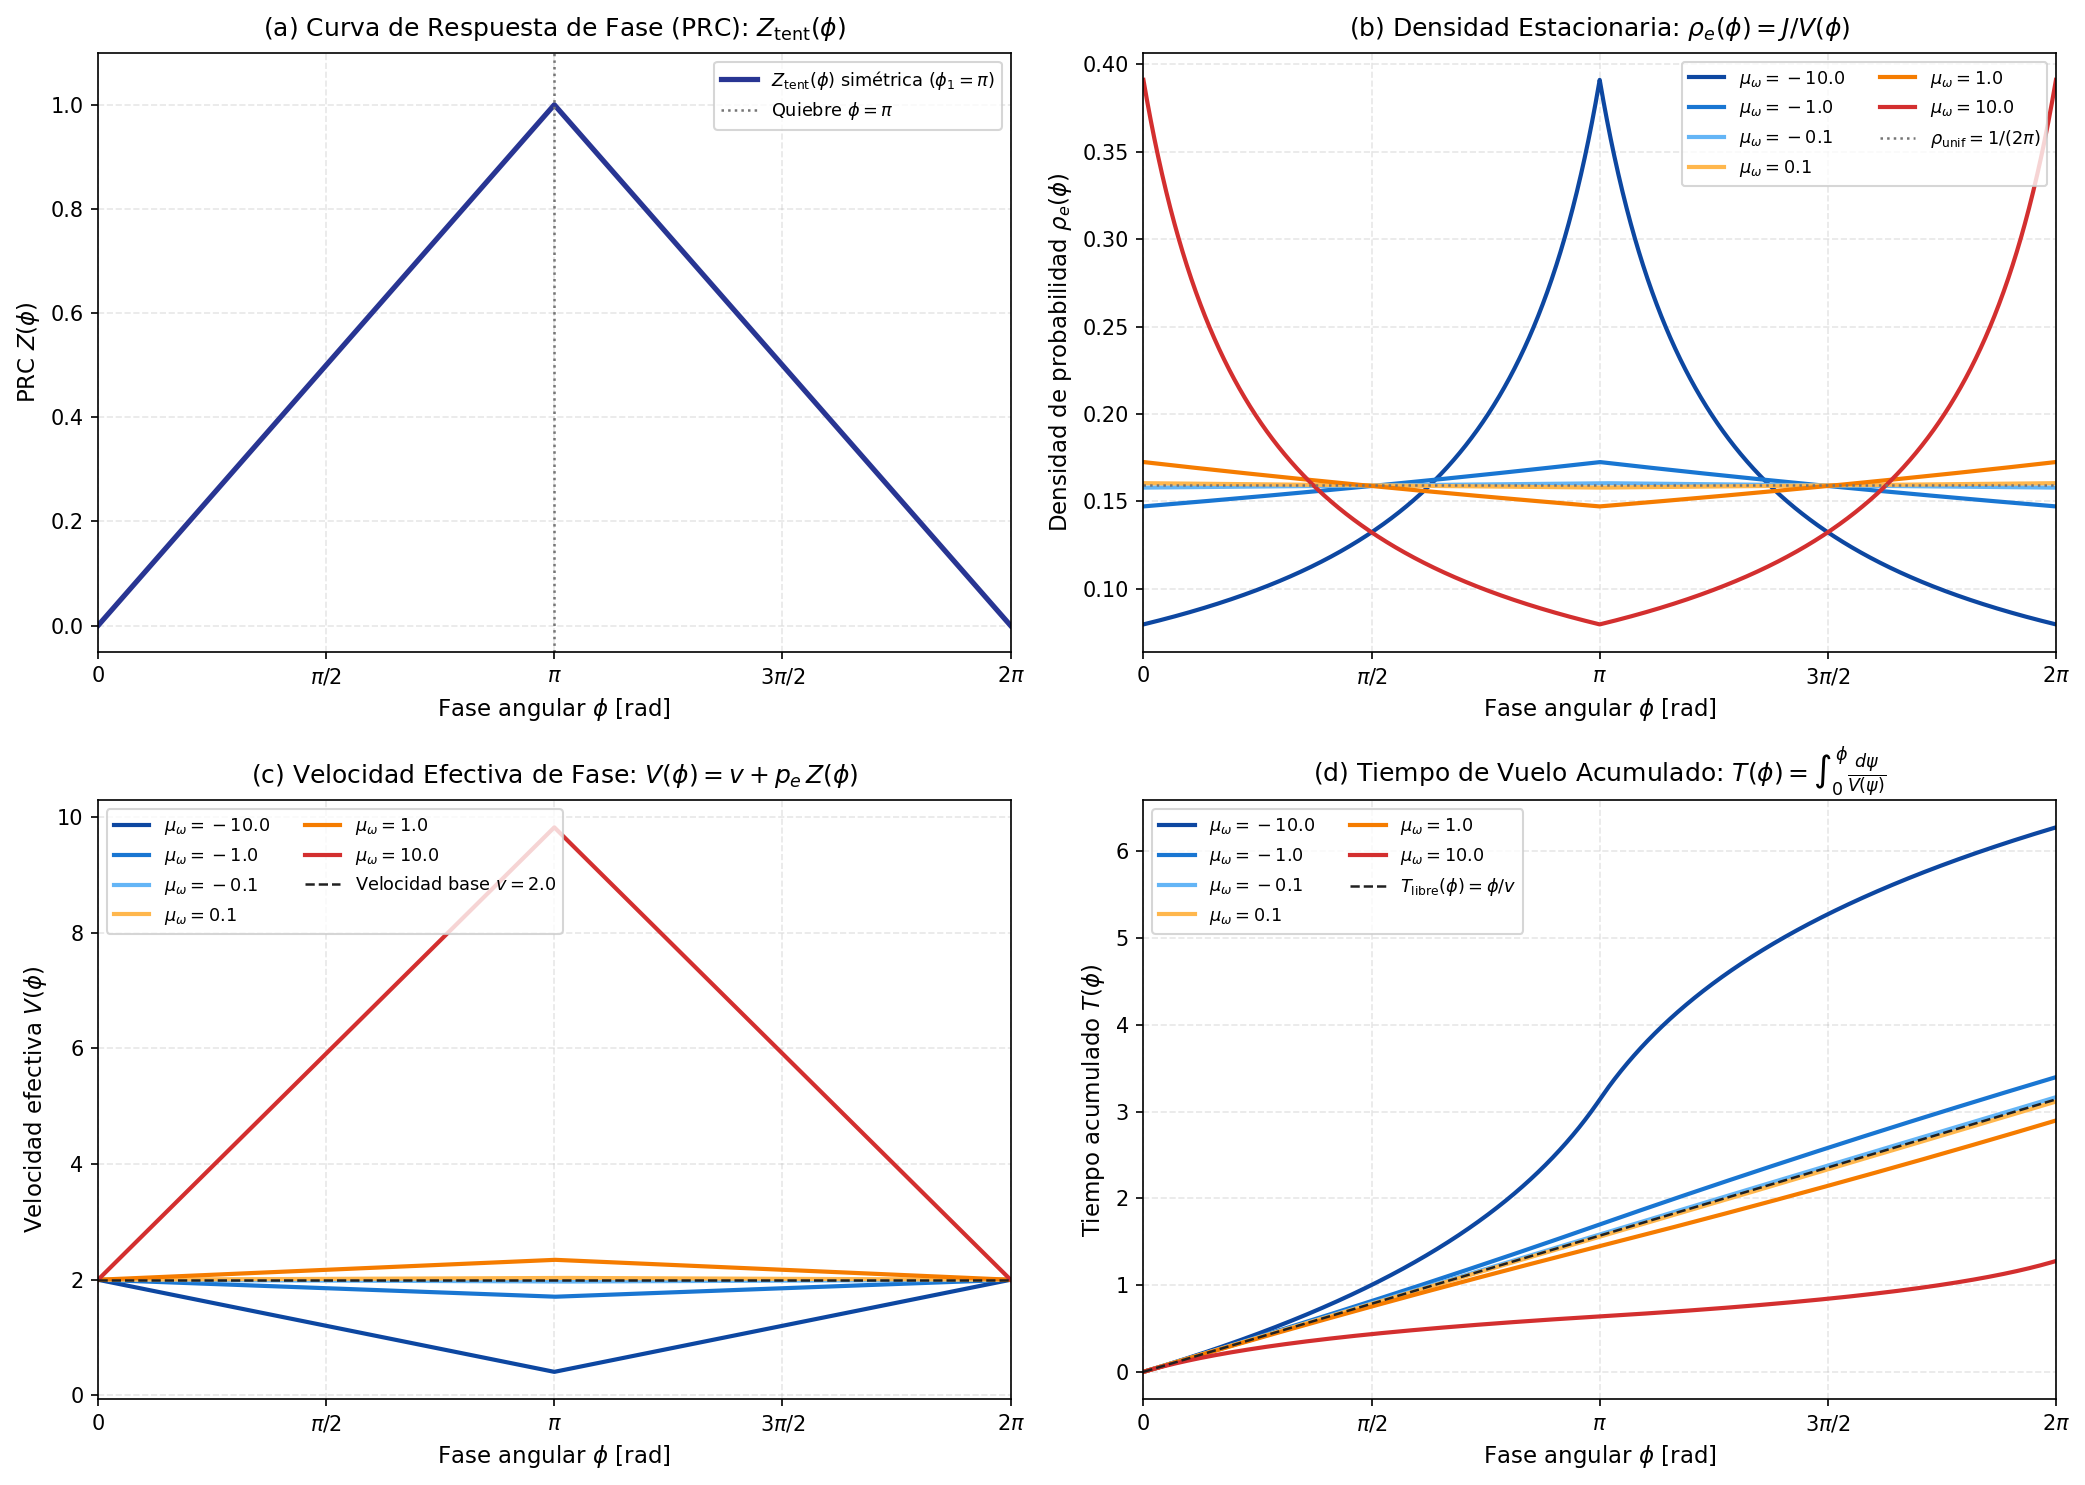

In [4]:
# ==============================================================================
# CARACTERIZACIÓN NUMÉRICA Y ANALÍTICA DEL ESTADO ESTACIONARIO - MODELO TENT SIMÉTRICO
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. PARÁMETROS GEOMÉTRICOS DE LA PRC TENT (VERSIÓN SIMÉTRICA)
# ------------------------------------------------------------------------------
_TENT_FRAC = 0.5                                 # Fracción del ciclo donde está el vértice: 0.5 -> vértice en phi = pi (tienda simétrica)
_TENT_PHI1 = _TENT_FRAC * 2.0 * np.pi            # Fase angular del vértice: phi_1 = 0.5 * 2*pi = pi
_TENT_A    = 1.0 / _TENT_PHI1                    # Pendiente del tramo ascendente: A = 1/phi_1 = 1/pi
_TENT_B    = 1.0 / (2.0 * np.pi - _TENT_PHI1)    # Módulo de la pendiente del tramo descendente: B = 1/(2pi - phi_1) = 1/pi

# Control de consistencia: la simetría Z(2pi - phi) = Z(phi) exige A = B (vértice en pi)
assert np.isclose(_TENT_A, _TENT_B), "La PRC tent no es simétrica: _TENT_FRAC debe ser 0.5."


# ------------------------------------------------------------------------------
# 2. DEFINICIÓN DE LA CURVA DE RESPUESTA DE FASE (PRC) - MODELO TENT
# ------------------------------------------------------------------------------
def Z_tent(phi):
    """
    Curva de Respuesta de Fase (PRC) triangular simétrica (modelo tent).

    Definición (con _TENT_FRAC = 0.5, A = B = 1/pi):
        Z_tent(phi) = A * phi            para phi in [0, pi]
        Z_tent(phi) = B * (2*pi - phi)   para phi in [pi, 2*pi]

    Propiedades físicas y geométricas:
    - Se anula en el instante del disparo y reseteo: Z(0) = Z(2*pi) = 0.
    - Alcanza su valor máximo unitario en el vértice: Z(pi) = 1.
    - Presenta simetría reflexiva respecto a pi: Z(phi) = Z(2*pi - phi).
    - Es continua pero no derivable en phi = pi (punto de quiebre).

    Parámetros:
    -----------
    phi : float o np.ndarray
        Fase o vector de fases en radianes en el intervalo [0, 2*pi].

    Devuelve:
    ---------
    float o np.ndarray : Amplitud de la respuesta de fase Z(phi).
    """
    phi_arr = np.asarray(phi, dtype=float)              # Convierte la entrada (escalar o vector) en arreglo de punto flotante
    Z_vals = np.where(phi_arr <= _TENT_PHI1,            # Selecciona la rama según la posición respecto del vértice
                      _TENT_A * phi_arr,                # Rama ascendente: A * phi
                      _TENT_B * (2.0 * np.pi - phi_arr))  # Rama descendente: B * (2pi - phi)
    return float(Z_vals) if Z_vals.ndim == 0 else Z_vals  # Devuelve escalar si la entrada era escalar (compatible con quad)


def Z_tent_derivada(phi):
    """
    Derivada de la PRC Z_tent con respecto a la fase phi.

        Z'(phi) = +A   para phi in [0, pi)
        Z'(phi) = -B   para phi in (pi, 2*pi]

    En el quiebre phi = pi la derivada no existe; se asigna el promedio de las
    derivadas laterales, (A - B)/2 = 0, que preserva la antisimetría
        Z'(phi) = - Z'(2*pi - phi).
    """
    phi_arr = np.asarray(phi, dtype=float)              # Convierte la entrada en arreglo de punto flotante
    dZ = np.where(phi_arr < _TENT_PHI1, _TENT_A, -_TENT_B)  # Pendiente lateral de cada rama
    dZ = np.where(np.isclose(phi_arr, _TENT_PHI1),      # Detecta los puntos ubicados exactamente en el quiebre
                  0.5 * (_TENT_A - _TENT_B), dZ)        # y les asigna el promedio de las derivadas laterales (= 0)
    return float(dZ) if dZ.ndim == 0 else dZ            # Devuelve escalar si la entrada era escalar


# Verificación numérica de las propiedades de la PRC sobre una malla de prueba
_phi_test = np.linspace(0.0, 2.0 * np.pi, 1001)                                  # Malla de prueba simétrica respecto de pi
assert np.isclose(Z_tent(0.0), 0.0) and np.isclose(Z_tent(2.0 * np.pi), 0.0)     # Anulación en el disparo
assert np.isclose(Z_tent(np.pi), 1.0)                                            # Máximo unitario en el vértice
assert np.allclose(Z_tent(_phi_test), Z_tent(2.0 * np.pi - _phi_test))           # Simetría reflexiva Z(2pi - phi) = Z(phi)


# ------------------------------------------------------------------------------
# 3. SOLUCIÓN ANALÍTICA CERRADA PARA rho_e(0) Y J EN EL MODELO TENT (BENCHMARK)
# ------------------------------------------------------------------------------
def rho_e0_analitico_tent(mu_w):
    """
    Densidad estacionaria en el origen para la PRC tent:

        rho_e(0) = [exp(mu_w / 2pi) - 1] / mu_w

    (independiente de v y del vértice, pues 1/A + 1/B = 2pi). En el límite
    desacoplado mu_w -> 0 se recupera la densidad uniforme 1/(2pi).
    """
    if np.isclose(mu_w, 0.0):                          # Caso desacoplado: límite analítico de la expresión
        return 1.0 / (2.0 * np.pi)                     # rho_e(0) = 1/(2pi)
    return np.expm1(mu_w / (2.0 * np.pi)) / mu_w       # expm1 evita la cancelación numérica cuando |mu_w| << 1


def J_analitico_tent(mu_w, v=V_BASE):
    """
    Flujo estacionario exacto para la PRC tent:  J = v * rho_e(0) = v (e^{mu_w/2pi} - 1) / mu_w.
    """
    return v * rho_e0_analitico_tent(mu_w)             # Relación J = v rho_e(0), válida porque Z_tent(0) = 0


def rho_e_tent(phi, mu_w, J, v=V_BASE):
    """
    Densidad estacionaria rho_e(phi) = J / V(phi) = rho_e(0) / [1 + mu_w rho_e(0) (Z(phi) - Z(0))].
    """
    rho_e0 = J / v                                                      # Densidad en el origen rho_e(0) = J / v
    return rho_e0 / (1.0 + mu_w * rho_e0 * (Z_tent(phi) - Z_tent(0.0)))  # Forma general con el término de no-bloqueo en el denominador


# ------------------------------------------------------------------------------
# 4. RESOLUCIÓN NUMÉRICA AUTOCONSISTENTE DE J (PARAMETRIZACIÓN SIN BLOQUEO)
# ------------------------------------------------------------------------------
U_MAX_TENT = 30.0   # Cota de búsqueda |u| <= 30: V_min / v >= e^{-30} ~ 1e-13, todavía representable frente a 1 en
                    # doble precisión (la raíz es u* = mu_w / 2pi, es decir |u*| <= 1.6 para |mu_w| <= 10)

def resolver_J_tent(mu_w, v=V_BASE):
    r"""
    Encuentra numéricamente el flujo estacionario J resolviendo:
        J * \int_0^{2*pi} [1 / (v + mu_w * J * Z_tent(phi))] dphi = 1

    Para garantizar la condición de no-bloqueo 1 + mu_w rho_e(0) Z_tent(phi) > 0
    en TODAS las evaluaciones, se busca la variable auxiliar
        u = ln[1 + mu_w J / v]   <=>   J(u) = v (e^u - 1) / mu_w,
    que cumple min_phi V(phi) = v * min(1, e^u) > 0 para cualquier u real.

    La integral se calcula con cuadratura adaptativa (scipy.integrate.quad),
    partiendo el dominio en el quiebre phi = pi, y el cero se halla con Brent.

    Parámetros:
    -----------
    mu_w : float
        Constante de acoplamiento sináptico medio.
    v : float
        Velocidad intrínseca base (fijada en 2.0).

    Devuelve:
    ---------
    float : Raíz numérica J que satisface la normalización unitaria.
    """
    # Caso particular desacoplado mu_w = 0: velocidad constante V(phi) = v
    if np.isclose(mu_w, 0.0):
        return v / (2.0 * np.pi)

    # Flujo J como función de la variable sin bloqueo u (expm1 para precisión en |u| << 1)
    def J_de_u(u):
        return v * np.expm1(u) / mu_w

    # Función residual R(u) = J(u) * integral [1 / V(phi)] dphi - 1 = 0
    def residual(u):
        J_cand = J_de_u(u)                                      # Flujo candidato asociado a u
        integral_val, _ = integrate.quad(
            lambda phi: 1.0 / (v + mu_w * J_cand * Z_tent(phi)),  # Recíproco de la velocidad efectiva 1/V(phi)
            0.0,                                                # Límite inferior de integración
            2.0 * np.pi,                                        # Límite superior de integración
            points=[_TENT_PHI1],                                # Partición explícita en el quiebre phi = pi
            epsabs=1e-13,                                       # Tolerancia absoluta estricta
            epsrel=1e-12,                                       # Tolerancia relativa estricta
            limit=500                                           # Subintervalos máximos (pico angosto de 1/V cerca de pi si mu_w << 0)
        )
        return J_cand * integral_val - 1.0                      # Desvío respecto de la normalización unitaria

    # Intervalo de búsqueda en u: el signo de u debe coincidir con el de mu_w para que J > 0
    # (inhibición: 0 < V_min/v = e^u < 1; excitación: V_min = v en phi = 0, u > 0).
    signo = np.sign(mu_w)                       # Signo de u impuesto por J > 0
    u_int = 1e-12                               # Extremo interior: J -> 0+, donde R(u) -> -1 < 0
    u_ext = 1.0                                 # Extremo exterior inicial |u| = 1
    # Bracket adaptativo: se duplica |u| hasta que R cambia de signo, evitando evaluar estados
    # con V_min innecesariamente pequeño (que degradan la cuadratura cerca de phi = pi)
    while residual(signo * u_ext) < 0.0:
        u_ext *= 2.0                            # Duplicación del extremo exterior
        if u_ext > U_MAX_TENT:                  # Salvaguarda: no se encontró cambio de signo en |u| <= U_MAX_TENT
            raise RuntimeError(f"No se pudo acotar la raíz en u para mu_w = {mu_w}")
    bracket_u = sorted([signo * u_int, signo * u_ext])  # Bracket ordenado [u_min, u_max]

    # Búsqueda de cero robusta mediante el método de Brent en la variable u
    solucion = optimize.root_scalar(
        residual,
        bracket=bracket_u,
        method='brentq',
        xtol=1e-14,
        rtol=1e-13
    )

    if not solucion.converged:
        raise RuntimeError(f"Error de convergencia en root_scalar para mu_w = {mu_w}")

    return float(J_de_u(solucion.root))         # Se devuelve el flujo J asociado a la raíz u*


# ------------------------------------------------------------------------------
# 5. TIEMPO DE VUELO ANALÍTICO T(phi) PARA LA PRC TENT
# ------------------------------------------------------------------------------
def tiempo_vuelo_analitico_tent(phi, mu_w, J, v=V_BASE):
    r"""
    Tiempo de vuelo acumulado exacto T(phi) = \int_0^phi dphi' / (v + p_e Z_tent(phi')).

        T(phi) = (pi / p_e) ln(1 + p_e phi / (pi v))       para phi in [0, pi]
        T(phi) = 2 T(pi) - T(2pi - phi)                   para phi in [pi, 2pi]

    con T(pi) = 1/(2J). Para p_e -> 0 se usa el límite T(phi) = phi / v.

    Parámetros:
    -----------
    phi : float o np.ndarray
        Fase angular en radianes en el intervalo [0, 2*pi].
    mu_w : float
        Constante de acoplamiento sináptico medio.
    J : float
        Flujo de probabilidad estacionario.
    v : float
        Velocidad intrínseca base (fijada en 2.0).

    Devuelve:
    ---------
    float o np.ndarray : Tiempo acumulado T(phi).
    """
    pe = mu_w * J                                            # Acoplamiento estacionario p_e = mu_w J
    phi_arr = np.asarray(phi, dtype=float)                   # Fases como arreglo de punto flotante
    phi_izq = np.minimum(phi_arr, 2.0 * np.pi - phi_arr)     # Fase reflejada a la primera mitad del ciclo [0, pi]

    def _T_mitad(ph):
        # T(ph) en [0, pi] escrito como (ph/v) * ln(1+x)/x con x = p_e ph/(pi v), estable cuando x -> 0
        x = pe * ph / (np.pi * v)                            # Argumento adimensional del logaritmo
        cociente = np.ones_like(x)                           # Límite ln(1+x)/x -> 1 cuando x -> 0
        mask = np.abs(x) > 1e-14                             # Puntos donde el cociente se puede evaluar sin cancelación
        cociente[mask] = np.log1p(x[mask]) / x[mask]         # log1p mantiene precisión cuando 1+x ~ 0 (inhibición fuerte)
        return (ph / v) * cociente                           # T(ph) = (ph/v) * ln(1+x)/x = (pi/p_e) ln(1+x)

    T_izq = _T_mitad(np.atleast_1d(phi_izq))                 # Tiempo de vuelo en la fase reflejada
    T_pi = _T_mitad(np.array([np.pi]))[0]                    # Tiempo de vuelo hasta el vértice T(pi)
    T_vals = np.where(np.atleast_1d(phi_arr) <= np.pi,       # Selección de rama según la mitad del ciclo
                      T_izq,                                 # Primera mitad: T(phi) directo
                      2.0 * T_pi - T_izq)                    # Segunda mitad: reflexión T(phi) = 2T(pi) - T(2pi - phi)
    return float(T_vals[0]) if phi_arr.ndim == 0 else T_vals  # Escalar si la entrada era escalar


# ------------------------------------------------------------------------------
# 6. EVALUACIÓN Y TABULACIÓN PARA EL CONJUNTO DE ACOPLAMIENTOS ESPECIFICADO
# ------------------------------------------------------------------------------
# Acoplamientos estudiados: mu_w = ±0.1, ±1, ±10 (mismo conjunto que en el análisis del QIF)
mu_valores_tent = [-10.0, -1.0, -0.1, 0.1, 1.0, 10.0]

# Malla angular de alta resolución (2001 puntos: el índice central cae exactamente en phi = pi)
N_PUNTOS_MALLA_TENT = 2001
phi_grid_tent = np.linspace(0.0, 2.0 * np.pi, N_PUNTOS_MALLA_TENT)

# Estructuras de almacenamiento para resultados tabulares y curvas
registros_tabla_tent = []
datos_graficos_tent = {}

# Paleta cromática coordinada (idéntica a la del QIF: de inhibición fuerte a excitación fuerte)
paleta_colores_tent = [
    '#0D47A1',  # mu_w = -10.0  (Azul marino profundo)
    '#1976D2',  # mu_w = -1.0   (Azul medio)
    '#64B5F6',  # mu_w = -0.1   (Azul celeste)
    '#FFB74D',  # mu_w = +0.1   (Naranja claro)
    '#F57C00',  # mu_w = +1.0   (Naranja intenso)
    '#D32F2F',  # mu_w = +10.0  (Rojo bermellón)
]

print("Iniciando resolución autoconsistente (modelo tent simétrico) para cada mu_w con v = 2.0...")

for mu_w, color in zip(mu_valores_tent, paleta_colores_tent):
    # 1. Cálculo del flujo numérico y analítico
    J_num = resolver_J_tent(mu_w, v=V_BASE)                  # Raíz numérica de la normalización
    J_exact = J_analitico_tent(mu_w, v=V_BASE)               # Solución cerrada exponencial
    error_abs = abs(J_num - J_exact)                         # Discrepancia absoluta numérico vs. exacto

    # 2. Acoplamiento estacionario constante y densidad en el origen
    p_e = mu_w * J_num                                       # p_e = mu_w J
    rho_e0 = J_num / V_BASE                                  # rho_e(0) = J / v

    # 3. Condición de no-bloqueo: margen min_phi {1 + mu_w rho_e(0) [Z(phi) - Z(0)]}
    #    Con 0 <= Z <= 1 el mínimo es min{1, 1 + mu_w rho_e(0)} (alcanzado en phi = 0 o phi = pi)
    margen_bloqueo = min(1.0, 1.0 + mu_w * rho_e0)           # Debe ser estrictamente positivo
    margen_teorico = min(1.0, np.exp(mu_w / (2.0 * np.pi)))  # Valor esperado analíticamente: min{1, e^{mu_w/2pi}}
    if margen_bloqueo <= 0.0:                                # Verificación física explícita
        raise RuntimeError(f"Bloqueo de fases detectado para mu_w = {mu_w}")

    # 4. Velocidad efectiva y densidad estacionaria sobre la malla
    V_perfil = V_BASE + p_e * Z_tent(phi_grid_tent)          # V(phi) = v + p_e Z_tent(phi)
    rho_perfil = rho_e_tent(phi_grid_tent, mu_w, J_num)      # rho_e(phi) = J / V(phi)

    # 5. Verificación numérica de la normalización (partida en el quiebre phi = pi)
    norma_rho, _ = integrate.quad(lambda ph: rho_e_tent(ph, mu_w, J_num), 0.0, 2.0 * np.pi,
                                  points=[_TENT_PHI1], epsabs=1e-13, epsrel=1e-12, limit=500)

    # 6. Tiempo de vuelo acumulado analítico sobre toda la malla [0, 2pi]
    T_perfil = tiempo_vuelo_analitico_tent(phi_grid_tent, mu_w, J_num)

    # 7. Tiempo de vuelo hasta el vértice: cuadratura adaptativa, expresión analítica y simetría 1/(2J)
    T_pi_quad, _ = integrate.quad(lambda phi_p: 1.0 / (V_BASE + p_e * Z_tent(phi_p)), 0.0, np.pi,
                                  epsabs=1e-13, epsrel=1e-12, limit=500)
    T_pi_anal = tiempo_vuelo_analitico_tent(np.pi, mu_w, J_num)
    T_2pi = 1.0 / J_num                                      # Por la normalización: T(2pi) = 1 / J

    # Almacenamiento para graficación y para el análisis de estabilidad posterior
    datos_graficos_tent[mu_w] = {
        'J': J_num,
        'p_e': p_e,
        'V': V_perfil,
        'rho': rho_perfil,
        'T': T_perfil,
        'T_pi': T_pi_anal,
        'color': color,
    }

    # Registro cuantitativo para DataFrame
    registros_tabla_tent.append({
        r'$\mu_\omega$ [u.v.]': mu_w,
        r'$J_{\rm num}$ [1/u.t.]': J_num,
        r'$J_{\rm exacto}$ [1/u.t.]': J_exact,
        r'Error $|J - J_{\rm ex}|$ [1/u.t.]': error_abs,
        r'$p_e = \mu_\omega J$ [u.v./u.t.]': p_e,
        r'$\rho_e(0) = J/v$ [1/rad]': rho_e0,
        r'$\min_\phi[1 + \mu_\omega \rho_e(0) Z]$': margen_bloqueo,
        r'$\min\{1, e^{\mu_\omega/2\pi}\}$': margen_teorico,
        r'$\int \rho_e \, d\phi$': norma_rho,
        r'$T(\pi)$ (quad) [u.t.]': T_pi_quad,
        r'$T(\pi)$ (analítico) [u.t.]': T_pi_anal,
        r'$T(2\pi) = 1/J$ [u.t.]': T_2pi,
    })

# Conversión a DataFrame de Pandas
df_estacionario_tent = pd.DataFrame(registros_tabla_tent)

# Visualización formal de la tabla en Jupyter
print("\n" + "="*80)
print("TABLA 3: ESTADO ESTACIONARIO - MODELO TENT SIMÉTRICO (_TENT_FRAC = 0.5, v = 2.0)")
print("="*80)
display(df_estacionario_tent.style.format({
    r'$J_{\rm num}$ [1/u.t.]': '{:.6e}',
    r'$J_{\rm exacto}$ [1/u.t.]': '{:.6e}',
    r'Error $|J - J_{\rm ex}|$ [1/u.t.]': '{:.2e}',
    r'$p_e = \mu_\omega J$ [u.v./u.t.]': '{:.6f}',
    r'$\rho_e(0) = J/v$ [1/rad]': '{:.6e}',
    r'$\min_\phi[1 + \mu_\omega \rho_e(0) Z]$': '{:.4e}',
    r'$\min\{1, e^{\mu_\omega/2\pi}\}$': '{:.4e}',
    r'$\int \rho_e \, d\phi$': '{:.10f}',
    r'$T(\pi)$ (quad) [u.t.]': '{:.6f}',
    r'$T(\pi)$ (analítico) [u.t.]': '{:.6f}',
    r'$T(2\pi) = 1/J$ [u.t.]': '{:.6f}',
}))

# ------------------------------------------------------------------------------
# 7. VISUALIZACIÓN MULTIPANEL COMBINADA (4 SUBPLOTS)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=STYLE['dpi'])

# Ticks angulares comunes en múltiplos de pi/2
ticks_pi = [0.0, 0.5 * np.pi, np.pi, 1.5 * np.pi, 2.0 * np.pi]

# ------------------------------------------------------------------------------
# PANEL 1: Curva de Respuesta de Fase (PRC) Z_tent(phi) vs phi
# ------------------------------------------------------------------------------
ax1 = axes[0, 0]
ax1.plot(phi_grid_tent, Z_tent(phi_grid_tent), color='#283593', lw=STYLE['lw_main'] + 0.5,
         label=r'$Z_{\rm tent}(\phi)$ simétrica ($\phi_1 = \pi$)')
ax1.axvline(np.pi, color='#757575', linestyle=':', lw=STYLE['lw_aux'], label=r'Quiebre $\phi = \pi$')  # Marca el punto de quiebre
ax1.set_title(r'(a) Curva de Respuesta de Fase (PRC): $Z_{\rm tent}(\phi)$', fontsize=STYLE['fontsize_title'], pad=8)
ax1.set_xlabel(r'Fase angular $\phi$ [rad]', fontsize=STYLE['fontsize_label'])
ax1.set_ylabel(r'PRC $Z(\phi)$ [rad/u.v.]', fontsize=STYLE['fontsize_label'])
ax1.set_xlim(0.0, 2.0 * np.pi)
ax1.set_ylim(-0.05, 1.1)
ax1.set_xticks(ticks_pi)
ax1.xaxis.set_major_formatter(pi_formatter)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.legend(loc='upper right', fontsize=STYLE['fontsize_legend'])

# ------------------------------------------------------------------------------
# PANEL 2: Densidad Estacionaria rho_e(phi) vs phi
# ------------------------------------------------------------------------------
ax2 = axes[0, 1]
for mu_w in mu_valores_tent:
    dat = datos_graficos_tent[mu_w]
    ax2.plot(phi_grid_tent, dat['rho'], color=dat['color'], lw=STYLE['lw_main'], label=rf'$\mu_\omega = {mu_w}$ u.v.')
# Línea de referencia: distribución uniforme desacoplada rho = 1 / (2*pi)
ax2.axhline(1.0 / (2.0 * np.pi), color='#757575', linestyle=':', lw=STYLE['lw_aux'], label=r'$\rho_{\rm unif} = 1/(2\pi)$')
ax2.set_title(r'(b) Densidad Estacionaria: $\rho_e(\phi) = J / V(\phi)$', fontsize=STYLE['fontsize_title'], pad=8)
ax2.set_xlabel(r'Fase angular $\phi$ [rad]', fontsize=STYLE['fontsize_label'])
ax2.set_ylabel(r'Densidad de probabilidad $\rho_e(\phi)$ [1/rad]', fontsize=STYLE['fontsize_label'])
ax2.set_xlim(0.0, 2.0 * np.pi)
ax2.set_xticks(ticks_pi)
ax2.xaxis.set_major_formatter(pi_formatter)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.legend(loc='upper right', fontsize=STYLE['fontsize_legend'], ncol=2)

# ------------------------------------------------------------------------------
# PANEL 3: Velocidad Efectiva V(phi) vs phi
# ------------------------------------------------------------------------------
ax3 = axes[1, 0]
for mu_w in mu_valores_tent:
    dat = datos_graficos_tent[mu_w]
    ax3.plot(phi_grid_tent, dat['V'], color=dat['color'], lw=STYLE['lw_main'], label=rf'$\mu_\omega = {mu_w}$ u.v.')
# Línea de referencia: velocidad base constante v = 2.0
ax3.axhline(V_BASE, color='#212121', linestyle='--', lw=STYLE['lw_aux'], label=rf'Velocidad base $v = {V_BASE:.1f}$ rad/u.t.')
ax3.set_title(r'(c) Velocidad Efectiva de Fase: $V(\phi) = v + p_e \, Z(\phi)$', fontsize=STYLE['fontsize_title'], pad=8)
ax3.set_xlabel(r'Fase angular $\phi$ [rad]', fontsize=STYLE['fontsize_label'])
ax3.set_ylabel(r'Velocidad efectiva $V(\phi)$ [rad/u.t.]', fontsize=STYLE['fontsize_label'])
ax3.set_xlim(0.0, 2.0 * np.pi)
ax3.set_xticks(ticks_pi)
ax3.xaxis.set_major_formatter(pi_formatter)
ax3.grid(True, alpha=0.3, linestyle='--')
ax3.legend(loc='upper left', fontsize=STYLE['fontsize_legend'], ncol=2)

# ------------------------------------------------------------------------------
# PANEL 4: Tiempo de Vuelo Acumulado T(phi) vs phi
# ------------------------------------------------------------------------------
ax4 = axes[1, 1]
for mu_w in mu_valores_tent:
    dat = datos_graficos_tent[mu_w]
    ax4.plot(phi_grid_tent, dat['T'], color=dat['color'], lw=STYLE['lw_main'], label=rf'$\mu_\omega = {mu_w}$ u.v.')
# Línea de referencia: tiempo de vuelo de los osciladores libres desacoplados
ax4.plot(phi_grid_tent, phi_grid_tent / V_BASE, color='#212121', linestyle='--', lw=STYLE['lw_aux'], label=r'$T_{\rm libre}(\phi) = \phi / v$')
ax4.set_title(r'(d) Tiempo de Vuelo Acumulado: $T(\phi) = \int_0^\phi \frac{d\phi^{\prime}}{V(\phi^{\prime})}$', fontsize=STYLE['fontsize_title'], pad=8)
ax4.set_xlabel(r'Fase angular $\phi$ [rad]', fontsize=STYLE['fontsize_label'])
ax4.set_ylabel(r'Tiempo acumulado $T(\phi)$ [u.t.]', fontsize=STYLE['fontsize_label'])
ax4.set_xlim(0.0, 2.0 * np.pi)
ax4.set_xticks(ticks_pi)
ax4.xaxis.set_major_formatter(pi_formatter)
ax4.grid(True, alpha=0.3, linestyle='--')
ax4.legend(loc='upper left', fontsize=STYLE['fontsize_legend'], ncol=2)

plt.tight_layout()
plt.show()

### Resolución Numérica de Autovalores Puramente Imaginarios ($s_n = i \nu_n$) para el Modelo Tent

#### ¿Qué hace esta celda?
1. Resuelve numéricamente, para la PRC triangular simétrica, la misma ecuación trascendental de la Sección 1.5 en el caso de modos colectivos puramente oscilatorios ($\lambda_n = 0 \implies s_n = i\nu_n$, $\nu_n > 0$):
   $$
   \text{LHS}(\nu) = \sin\left[\nu\,T(\pi)\right], \qquad
   \text{RHS}(\nu) = \mu_\omega J\,\nu\int_0^\pi \frac{Z_{\rm tent}(\phi')}{V^2(\phi')}\cos\left[\nu\{T(\phi') - T(\pi)\}\right] d\phi'
   $$
2. Halla las frecuencias $\nu_n \in [0.01, 15]$ rad/u.t. que satisfacen $\text{LHS}(\nu_n) = \text{RHS}(\nu_n)$ para cada $\mu_\omega \in \{-10, -1, -0.1, 0.1, 1, 10\}$, con $v = 2.0$.
3. Valida cada raíz numérica contra la ecuación trascendental cerrada de la Sección 2.5, $a\cos[\nu T(\pi)] + \nu\sin[\nu T(\pi)] = a\,e^{-\mu_\omega/2\pi}$.
4. Grafica $\text{LHS}(\nu)$ y $\text{RHS}(\nu)$ en una cuadrícula de 6 paneles ($3\times 2$), uno por $\mu_\omega$, marcando las intersecciones.

#### ¿Cómo lo hace?
* **Tiempo de vuelo:** reutiliza `tiempo_vuelo_analitico_tent` (celda anterior) y define su inversa exacta $\phi(T) = \frac{\pi v}{p_e}\left(e^{p_e T/\pi} - 1\right)$ en `fase_de_tiempo_tent`.
* **Cálculo numérico del RHS (`calcular_RHS_tent`):** aplica el cambio de variable exacto $d\phi' = V(\phi')\,dT$ e integra con `scipy.integrate.quad` en $T \in [0, T(\pi)]$ el integrando
  $\frac{Z_{\rm tent}(\phi(T))}{V(\phi(T))}\cos[\nu(T - T(\pi))]$. $Z_{\rm tent}$ se evalúa numéricamente sobre $\phi(T)$, y la velocidad sobre la trayectoria se calcula como $V = d\phi/dT = v\,e^{p_e T/\pi}$, que es idéntica a $v + p_e Z_{\rm tent}(\phi(T))$ pero evita la cancelación catastrófica $v + p_e Z \approx 0$ cerca del vértice cuando $\mu_\omega \ll 0$. El integrando resultante es suave en todo el intervalo. Como la integral sólo abarca $[0, \pi]$, el quiebre de $Z_{\rm tent}$ queda en el extremo superior y no degrada la cuadratura.
* **Benchmark analítico (`calcular_RHS_tent_cerrado`):** implementa la expresión cerrada del RHS y se compara con la cuadratura sobre toda la malla de $\nu$.
* **LHS:** reutiliza la función genérica `calcular_LHS(nu, T_pi)` definida en el análisis del QIF.
* **Escaneo y refinamiento:** evalúa $f(\nu) = \text{LHS} - \text{RHS}$ en una malla de 350 puntos (misma resolución que en el QIF), detecta cambios de signo y refina cada raíz con Brent (`brentq`, tolerancia $10^{-10}$). Cada raíz se recalcula también sobre la ecuación cerrada para medir la discrepancia $|\nu_n^{\rm num} - \nu_n^{\rm cerrado}|$.
* **Visualización:** misma convención que el QIF (LHS azul continuo, RHS rojo discontinuo, raíces en verde y línea guía en el modo fundamental $\nu_1$).

#### ¿Qué devuelve?
* Un panel de 6 gráficos ($3 \times 2$) con las curvas $\text{LHS}(\nu)$ y $\text{RHS}(\nu)$ y sus intersecciones para cada $\mu_\omega$.
* Dos tablas (`pandas.DataFrame`):
  1. **Tabla Resumen:** $\mu_\omega$, $J$, $p_e$, $T(\pi)$, $a = p_e/\pi$, máximo error de la cuadratura del RHS frente a la forma cerrada, número de raíces, modo fundamental $\nu_1$, su período $T_{\rm modo,1} = 2\pi/\nu_1$ y la lista de raíces.
  2. **Tabla Detallada:** para cada modo $n$, $\nu_n$, $T_{\rm modo}$, $\text{LHS}(\nu_n)$, $\text{RHS}(\nu_n)$, el residuo $|\text{LHS} - \text{RHS}|$ y la discrepancia con la raíz de la ecuación cerrada.

Buscando soluciones nu_n de la ecuacion trascendental (modelo tent) para cada mu_w con v = 2.0...

TABLA 4: RESUMEN DE FRECUENCIAS nu_n Y PERÍODOS T_modo - MODELO TENT SIMÉTRICO (v = 2.0)


,$\mu_\omega$,$J$,$p_e = \mu_\omega J$,$T(\pi)$,$a = p_e/\pi$,Error rel. RHS (quad vs cerrado),Total raíces,$\nu_1$ (fundamental) [rad/s],"$T_{\rm modo, 1}$ [s]",Raíces $\nu_n$ [rad/s]
0,-10.000000,1.592780e-01,-1.592780,3.139165,-0.506998,1.38e-14,12,3.317000,1.894237,"[3.317, 3.8214, 5.1933, 5.8936, 7.1412, 7.9249, 9.1127, 9.9434, 11.0951, 11.956, 13.0833, 13.9653]"
1,-1.000000,2.942716e-01,-0.294272,1.699111,-0.093670,8.05e-16,8,1.911572,3.286920,"[1.9116, 3.6954, 5.5684, 7.3946, 9.2578, 11.0929, 12.952, 14.7911]"
2,-0.100000,3.157902e-01,-0.031579,1.583329,-0.010052,2.84e-16,7,1.990598,3.156431,"[1.9906, 3.9683, 5.9547, 7.9367, 9.9221, 11.905, 13.8901]"
3,0.100000,3.208564e-01,0.032086,1.558329,0.010213,3.19e-16,7,2.009529,3.126696,"[2.0095, 4.032, 6.0458, 8.064, 10.0787, 12.096, 14.1111]"
4,1.000000,3.450392e-01,0.345039,1.449111,0.109829,6.60e-16,6,2.101176,2.990319,"[2.1012, 4.3333, 6.4822, 8.6705, 10.8268, 13.0068]"
5,10.000000,7.822706e-01,7.822706,0.639165,2.490045,6.66e-16,3,3.841817,1.635472,"[3.8418, 9.5104, 14.4238]"



TABLA 5: DETALLE POR MODO Y VALIDACIÓN CONTRA LA ECUACIÓN CERRADA - MODELO TENT


,$\mu_\omega$,Modo $n$,$\nu_n$ [rad/s],$T_{\rm modo} = 2\pi/\nu_n$,LHS($\nu_n$),RHS($\nu_n$),|LHS - RHS|,$|\nu_n - \nu_n^{\rm cerrado}|$
0,-10.000000,1,3.31700004,1.894237,-0.834835,-0.834835,5.80e-14,1.24e-14
1,-10.000000,2,3.82140258,1.644209,-0.539933,-0.539933,8.88e-15,1.07e-14
2,-10.000000,3,5.19333819,1.209855,-0.560329,-0.560329,1.33e-15,1.78e-15
3,-10.000000,4,5.89356741,1.066109,-0.341653,-0.341653,8.33e-16,8.88e-16
4,-10.000000,5,7.14115515,0.879856,-0.413337,-0.413337,7.77e-15,0.00e+00
5,-10.000000,6,7.92493743,0.792837,-0.252298,-0.252298,4.12e-11,1.40e-11
6,-10.000000,7,9.11269213,0.689498,-0.325850,-0.325850,6.22e-13,1.31e-13
7,-10.000000,8,9.94343743,0.631893,-0.200468,-0.200468,1.66e-11,5.50e-12
8,-10.000000,9,11.09508368,0.566304,-0.268446,-0.268446,1.13e-13,2.13e-14
9,-10.000000,10,11.95600722,0.525525,-0.166454,-0.166454,1.32e-12,4.33e-13


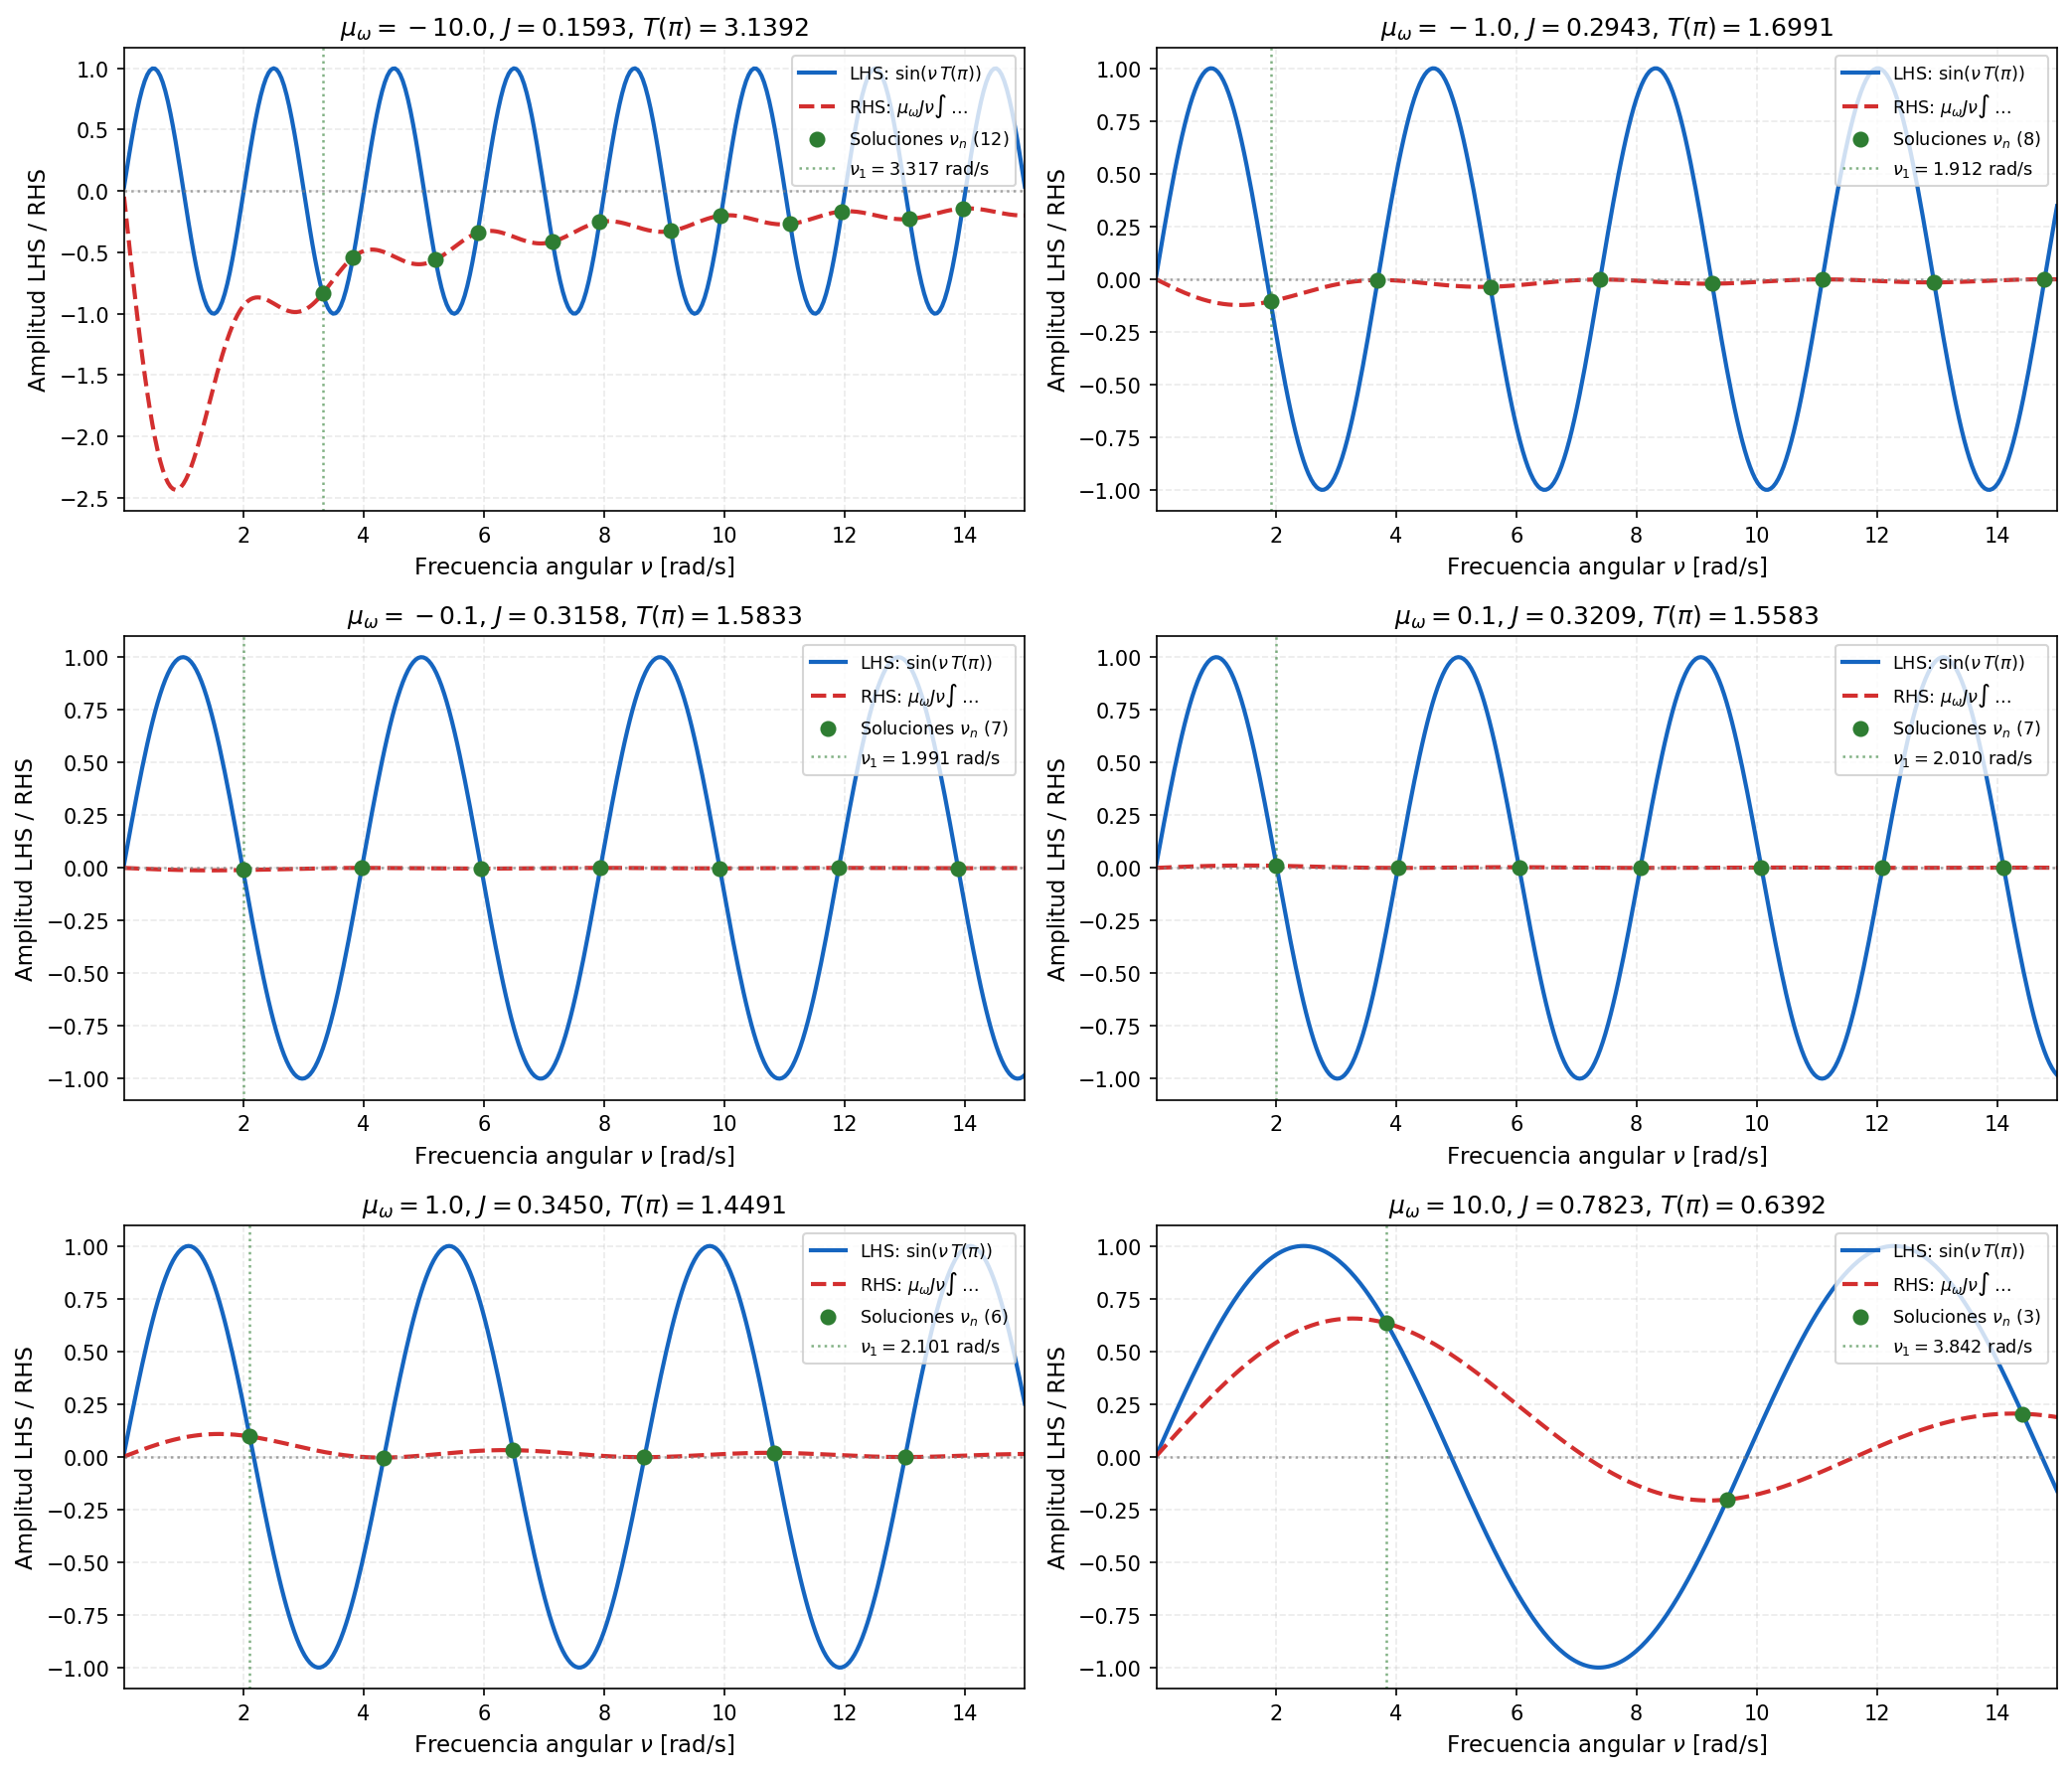

In [5]:
# ==============================================================================
# RESOLUCIÓN NUMÉRICA DE LA ECUACIÓN TRASCENDENTAL: AUTOVALORES IMAGINARIOS
# s_n = i * nu_n (nu_n in Real) - MODELO TENT SIMÉTRICO
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. TIEMPO DE VUELO INVERSO phi(T) PARA LA PRC TENT
# ------------------------------------------------------------------------------
def fase_de_tiempo_tent(T, mu_w, J, v=V_BASE):
    r"""
    Inversa exacta del tiempo de vuelo en la primera mitad del ciclo:

        phi(T) = (pi v / p_e) * (exp(p_e T / pi) - 1),    T in [0, T(pi)]

    Para p_e -> 0 se usa el límite phi(T) = v T (vuelo libre).

    Parámetros:
    -----------
    T : float o np.ndarray
        Tiempo de vuelo transcurrido desde el disparo, en [0, T(pi)].
    mu_w : float
        Constante de acoplamiento sináptico medio.
    J : float
        Flujo de probabilidad estacionario.
    v : float
        Velocidad intrínseca base (fijada en 2.0).

    Devuelve:
    ---------
    float o np.ndarray : Fase phi(T) en [0, pi].
    """
    pe = mu_w * J                                     # Acoplamiento estacionario p_e = mu_w J
    if np.isclose(pe, 0.0, atol=1e-15):               # Límite desacoplado: avance libre a velocidad v
        return v * np.asarray(T, dtype=float)
    a = pe / np.pi                                    # Tasa exponencial a = p_e / pi
    return (v / a) * np.expm1(a * np.asarray(T, dtype=float))  # phi(T) = (v/a)(e^{aT} - 1), expm1 para precisión con aT << 1


# ------------------------------------------------------------------------------
# 2. LADO DERECHO RHS(nu): CUADRATURA NUMÉRICA EN LA VARIABLE TIEMPO DE VUELO
# ------------------------------------------------------------------------------
def calcular_RHS_tent(nu, mu_w, J, v=V_BASE):
    r"""
    Lado derecho (RHS) de la ecuación trascendental para autovalores imaginarios:

        RHS(nu) = mu_w J nu \int_0^pi [Z(phi')/V^2(phi')] cos[nu (T(phi') - T(pi))] dphi'

    calculado con el cambio de variable exacto dphi' = V(phi') dT:

        RHS(nu) = mu_w J nu \int_0^{T(pi)} [Z(phi(T))/V(phi(T))] cos[nu (T - T(pi))] dT

    El integrando en T es suave y acotado, lo que evita el pico angosto de Z/V^2
    en phi' -> pi para acoplamientos fuertemente inhibidores.

    Parámetros:
    -----------
    nu : float
        Frecuencia angular candidata [rad/u.t.].
    mu_w : float
        Constante de acoplamiento sináptico medio.
    J : float
        Flujo de probabilidad estacionario.
    v : float
        Velocidad intrínseca base (v = 2.0).

    Devuelve:
    ---------
    float : Amplitud del término de acoplamiento sináptico RHS(nu).
    """
    if np.isclose(nu, 0.0):                                       # Modo trivial nu = 0: RHS se anula idénticamente
        return 0.0

    pe = mu_w * J                                                 # Acoplamiento estacionario p_e = mu_w J
    T_pi = tiempo_vuelo_analitico_tent(np.pi, mu_w, J, v=v)       # Tiempo de vuelo hasta el vértice, T(pi) = 1/(2J)

    a = pe / np.pi                                                # Tasa exponencial a = p_e / pi

    # Integrando sobre T in [0, T(pi)]
    def integrando(T):
        phi_T = fase_de_tiempo_tent(T, mu_w, J, v=v)              # Fase alcanzada tras un tiempo T
        # Velocidad sobre la trayectoria: V(phi(T)) = dphi/dT = v e^{aT}. Es idéntica a v + p_e Z(phi(T)),
        # pero evita la cancelación catastrófica v + p_e Z ~ 0 cerca de phi = pi cuando mu_w << 0
        V_T = v * np.exp(a * T)
        return (Z_tent(phi_T) / V_T) * np.cos(nu * (T - T_pi))    # Núcleo [Z/V] cos(nu (T - T(pi)))

    # Cuadratura adaptativa sobre [0, T(pi)]; limit alto porque cos oscila ~ nu T(pi)/(2pi) veces
    integral_val, _ = integrate.quad(integrando, 0.0, T_pi, epsabs=1e-12, epsrel=1e-11, limit=500)

    return mu_w * J * nu * integral_val                           # RHS = mu_w J nu * integral


# ------------------------------------------------------------------------------
# 3. BENCHMARK ANALÍTICO: RHS(nu) EN FORMA CERRADA Y ECUACIÓN REDUCIDA
# ------------------------------------------------------------------------------
def calcular_RHS_tent_cerrado(nu, mu_w, J, v=V_BASE):
    r"""
    Forma cerrada del RHS para la PRC tent simétrica (Sección 2.5):

        RHS(nu) = sin(nu T_pi) - nu [a cos(nu T_pi) + nu sin(nu T_pi) - a e^{-a T_pi}] / (a^2 + nu^2)

    con a = p_e/pi, T_pi = T(pi) y e^{-a T_pi} = v / (v + p_e).
    """
    nu = np.asarray(nu, dtype=float)                              # Admite escalar o vector de frecuencias
    pe = mu_w * J                                                 # Acoplamiento estacionario
    a = pe / np.pi                                                # Tasa exponencial a = p_e / pi
    T_pi = tiempo_vuelo_analitico_tent(np.pi, mu_w, J, v=v)       # Tiempo de vuelo hasta el vértice
    exp_aT = v / (v + pe)                                         # e^{-a T(pi)} = v / V(pi), exacto por la forma de T(pi)
    numerador = a * np.cos(nu * T_pi) + nu * np.sin(nu * T_pi) - a * exp_aT  # Ecuación reducida g(nu)
    return np.sin(nu * T_pi) - nu * numerador / (a**2 + nu**2)   # RHS = LHS - nu g(nu)/(a^2 + nu^2)


def ecuacion_cerrada_tent(nu, mu_w, J, v=V_BASE):
    r"""
    Ecuación trascendental reducida (equivalente a LHS = RHS para nu != 0):

        g(nu) = a cos(nu T_pi) + nu sin(nu T_pi) - a e^{-a T_pi} = 0
    """
    pe = mu_w * J                                                 # Acoplamiento estacionario
    a = pe / np.pi                                                # Tasa exponencial
    T_pi = tiempo_vuelo_analitico_tent(np.pi, mu_w, J, v=v)       # Tiempo de vuelo hasta el vértice
    return a * np.cos(nu * T_pi) + nu * np.sin(nu * T_pi) - a * v / (v + pe)  # g(nu)


# ------------------------------------------------------------------------------
# 4. ESCANEO Y BÚSQUEDA SISTEMÁTICA DE RAÍCES nu_n EN (0, nu_max]
# ------------------------------------------------------------------------------
# Rango de escaneo de frecuencias angulares (mismo rango que en el QIF)
NU_MIN_TENT = 0.01
NU_MAX_TENT = 15.0
N_SCAN_TENT = 350                                    # Misma resolución que el QIF (paso ~0.043 rad/u.t.)
nu_malla_tent = np.linspace(NU_MIN_TENT, NU_MAX_TENT, N_SCAN_TENT)

# Diccionario para almacenar curvas y soluciones por cada mu_w
soluciones_trascendental_tent = {}
filas_resumen_tent = []
filas_detalladas_tent = []

print("Buscando soluciones nu_n de la ecuacion trascendental (modelo tent) para cada mu_w con v = 2.0...")

for mu_w in mu_valores_tent:
    # 1. Recuperamos J, p_e y T(pi) del estado estacionario calculado en la celda anterior
    J = datos_graficos_tent[mu_w]['J']               # Flujo estacionario numérico
    pe = mu_w * J                                    # Acoplamiento estacionario p_e
    T_pi = datos_graficos_tent[mu_w]['T_pi']         # Tiempo de vuelo al vértice, T(pi) = 1/(2J)

    # 2. Evaluación de LHS y RHS (numérico y cerrado) sobre la malla de frecuencias
    lhs_curva = calcular_LHS(nu_malla_tent, T_pi)                                          # LHS(nu) = sin(nu T(pi))
    rhs_curva = np.array([calcular_RHS_tent(nu, mu_w, J, v=V_BASE) for nu in nu_malla_tent])  # RHS por cuadratura
    rhs_cerrado = calcular_RHS_tent_cerrado(nu_malla_tent, mu_w, J, v=V_BASE)               # RHS analítico
    diff_curva = lhs_curva - rhs_curva                                                       # f(nu) = LHS - RHS

    # Error relativo máximo de la cuadratura respecto de la forma cerrada (escala: max(1, |RHS|))
    err_rhs = np.max(np.abs(rhs_curva - rhs_cerrado) / np.maximum(1.0, np.abs(rhs_cerrado)))

    # Función residual para el solver de alta precisión: f(nu) = LHS(nu) - RHS(nu) = 0
    def f_residuo(nu_cand):
        return calcular_LHS(nu_cand, T_pi) - calcular_RHS_tent(nu_cand, mu_w, J, v=V_BASE)

    # Función residual de la ecuación cerrada g(nu) = 0 (benchmark)
    def g_residuo(nu_cand):
        return ecuacion_cerrada_tent(nu_cand, mu_w, J, v=V_BASE)

    # 3. Detección de cambios de signo en la malla para delimitar brackets
    raices_encontradas = []                          # Raíces obtenidas con el RHS por cuadratura
    raices_cerradas = []                             # Raíces de la ecuación cerrada en el mismo bracket
    for i in range(len(nu_malla_tent) - 1):
        if diff_curva[i] * diff_curva[i+1] < 0.0:    # Cambio de signo de f entre nodos consecutivos
            br_a = nu_malla_tent[i]                  # Extremo izquierdo del bracket
            br_b = nu_malla_tent[i+1]                # Extremo derecho del bracket
            # Refinamiento mediante método de Brent sobre la ecuación con RHS numérico
            sol_root = optimize.root_scalar(f_residuo, bracket=[br_a, br_b], method='brentq', xtol=1e-10)
            if sol_root.converged:
                raices_encontradas.append(float(sol_root.root))
                # Raíz de la ecuación cerrada en el mismo bracket (g y f tienen los mismos ceros para nu > 0)
                if g_residuo(br_a) * g_residuo(br_b) < 0.0:
                    sol_g = optimize.root_scalar(g_residuo, bracket=[br_a, br_b], method='brentq', xtol=1e-12)
                    raices_cerradas.append(float(sol_g.root))
                else:
                    raices_cerradas.append(np.nan)   # No debería ocurrir; se marca para inspección

    # 4. Almacenamiento de curvas y raíces
    soluciones_trascendental_tent[mu_w] = {
        'J': J,
        'pe': pe,
        'T_pi': T_pi,
        'nu_malla': nu_malla_tent,
        'lhs': lhs_curva,
        'rhs': rhs_curva,
        'rhs_cerrado': rhs_cerrado,
        'raices': raices_encontradas,
        'raices_cerradas': raices_cerradas,
    }

    # 5. Registro para tabla resumen
    nu_1 = raices_encontradas[0] if len(raices_encontradas) > 0 else np.nan          # Modo fundamental
    T_modo_1 = (2.0 * np.pi / nu_1) if len(raices_encontradas) > 0 else np.nan       # Período colectivo del modo fundamental
    filas_resumen_tent.append({
        r'$\mu_\omega$ [u.v.]': mu_w,
        r'$J$ [1/u.t.]': J,
        r'$p_e = \mu_\omega J$ [u.v./u.t.]': pe,
        r'$T(\pi)$ [u.t.]': T_pi,
        r'$a = p_e/\pi$ [1/u.t.]': pe / np.pi,
        r'Error rel. RHS (quad vs cerrado)': err_rhs,
        r'Total raíces': len(raices_encontradas),
        r'$\nu_1$ (fundamental) [rad/u.t.]': nu_1,
        r'$T_{\rm modo, 1}$ [u.t.]': T_modo_1,
        r'Raíces $\nu_n$ [rad/u.t.]': [round(r, 4) for r in raices_encontradas],
    })

    # 6. Registros para tabla detallada por modo
    for idx_m, (r, r_c) in enumerate(zip(raices_encontradas, raices_cerradas), 1):
        lhs_r = calcular_LHS(r, T_pi)                                # LHS evaluado en la raíz
        rhs_r = calcular_RHS_tent(r, mu_w, J, v=V_BASE)              # RHS evaluado en la raíz
        filas_detalladas_tent.append({
            r'$\mu_\omega$ [u.v.]': mu_w,
            r'Modo $n$': idx_m,
            r'$\nu_n$ [rad/u.t.]': r,
            r'$T_{\rm modo} = 2\pi/\nu_n$ [u.t.]': 2.0 * np.pi / r,
            r'LHS($\nu_n$)': lhs_r,
            r'RHS($\nu_n$)': rhs_r,
            r'|LHS - RHS|': abs(lhs_r - rhs_r),
            r'$|\nu_n - \nu_n^{\rm cerrado}|$': abs(r - r_c),
        })

# Construcción de DataFrames de Pandas
df_resumen_modos_tent = pd.DataFrame(filas_resumen_tent)
df_detallado_modos_tent = pd.DataFrame(filas_detalladas_tent)

# Visualización formal de las tablas
print("\n" + "="*95)
print("TABLA 4: RESUMEN DE FRECUENCIAS nu_n Y PERÍODOS T_modo - MODELO TENT SIMÉTRICO (v = 2.0)")
print("="*95)
display(df_resumen_modos_tent.style.format({
    r'$J$ [1/u.t.]': '{:.6e}',
    r'$p_e = \mu_\omega J$ [u.v./u.t.]': '{:.6f}',
    r'$T(\pi)$ [u.t.]': '{:.6f}',
    r'$a = p_e/\pi$ [1/u.t.]': '{:.6f}',
    r'Error rel. RHS (quad vs cerrado)': '{:.2e}',
    r'$\nu_1$ (fundamental) [rad/u.t.]': '{:.6f}',
    r'$T_{\rm modo, 1}$ [u.t.]': '{:.6f}',
}))

print("\n" + "="*95)
print("TABLA 5: DETALLE POR MODO Y VALIDACIÓN CONTRA LA ECUACIÓN CERRADA - MODELO TENT")
print("="*95)
display(df_detallado_modos_tent.style.format({
    r'$\nu_n$ [rad/u.t.]': '{:.8f}',
    r'$T_{\rm modo} = 2\pi/\nu_n$ [u.t.]': '{:.6f}',
    r'LHS($\nu_n$)': '{:.6f}',
    r'RHS($\nu_n$)': '{:.6f}',
    r'|LHS - RHS|': '{:.2e}',
    r'$|\nu_n - \nu_n^{\rm cerrado}|$': '{:.2e}',
}))

# ------------------------------------------------------------------------------
# 5. VISUALIZACIÓN GRÁFICA MULTIPANEL: INTERSECCIONES LHS(nu) vs RHS(nu)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(3, 2, figsize=(14, 12), dpi=STYLE['dpi'])
axes = axes.flatten()

for idx, mu_w in enumerate(mu_valores_tent):
    ax = axes[idx]
    sol = soluciones_trascendental_tent[mu_w]

    # Curva LHS(nu) = sin(nu * T(pi))
    ax.plot(sol['nu_malla'], sol['lhs'], color='#1565C0', lw=STYLE['lw_main'], label=r'LHS: $\sin(\nu \, T(\pi))$')

    # Curva RHS(nu) = mu_w * J * nu * \int ... (cuadratura numérica)
    ax.plot(sol['nu_malla'], sol['rhs'], color='#D32F2F', lw=STYLE['lw_main'], linestyle='--', label=r'RHS: $\mu_\omega J \nu \int \dots$')

    # Línea horizontal cero de referencia
    ax.axhline(0.0, color='gray', linestyle=':', lw=STYLE['lw_aux'], alpha=0.7)

    # Marcado explícito de los puntos de intersección encontrados (soluciones nu_n)
    raices = sol['raices']
    if len(raices) > 0:
        lhs_raices = [calcular_LHS(r, sol['T_pi']) for r in raices]
        ax.scatter(raices, lhs_raices, color='#2E7D32', s=45, zorder=5, label=f'Soluciones $\\nu_n$ ({len(raices)})')

        # Línea guía vertical y anotación para el modo fundamental nu_1
        nu_fund = raices[0]
        ax.axvline(nu_fund, color='#2E7D32', linestyle=':', lw=1.2, alpha=0.6, label=rf'$\nu_1 = {nu_fund:.3f}$ rad/u.t.')

    # Configuración de títulos, ejes y formato
    ax.set_title(rf'$\mu_\omega = {mu_w}$ u.v., $J = {sol["J"]:.4f}$ u.t.$^{{-1}}$, $T(\pi) = {sol["T_pi"]:.4f}$ u.t.', fontsize=STYLE['fontsize_title'], pad=6)
    ax.set_xlabel(r'Frecuencia angular $\nu$ [rad/u.t.]', fontsize=STYLE['fontsize_label'])
    ax.set_ylabel(r'Amplitud LHS / RHS [adim.]', fontsize=STYLE['fontsize_label'])
    ax.set_xlim(NU_MIN_TENT, NU_MAX_TENT)
    ax.grid(True, alpha=0.25, linestyle='--')
    ax.legend(loc='upper right', fontsize=STYLE['fontsize_legend'])

plt.tight_layout()
plt.show()